**Big Data-Driven Solar PV Forecasting in Saudi Arabia — revised pipeline (MMAI 2026 resubmission)**

## Turn 1 — EDA

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Upload dataset (Colab) — skipped automatically when running locally
import os
DATA = '/content/KSAsolar2024.csv' if os.path.exists('/content') else '../data/KSAsolar2024.csv'
try:
    from google.colab import files
    if not os.path.exists(DATA): files.upload()
except ImportError:
    pass


In [3]:
df = pd.read_csv(DATA, encoding='latin1')

df.head()

,Date,City,Latitude,Longitude,Temperature (°C),Weather,Panel Type,Mount Type,Tilt (°),Panel Efficiency (%),Solar Irradiance (kWh/m²/day),Output Power (W),Estimated Daily Output (kWh)
0,1/1/2024,Riyadh,24.7136,46.6753,18,few clouds,Monocrystalline,Rooftop,25,22,5.39,1.90,21.06
1,1/1/2024,Riyadh,24.7136,46.6753,18,few clouds,Polycrystalline,Rooftop,25,18,5.39,1.55,21.06
2,1/1/2024,Riyadh,24.7136,46.6753,18,few clouds,Thin-Film,Rooftop,25,12,5.39,1.04,21.06
3,1/1/2024,Riyadh,24.7136,46.6753,18,few clouds,Monocrystalline,Ground,15,22,4.97,1.75,19.47
4,1/1/2024,Riyadh,24.7136,46.6753,18,few clouds,Polycrystalline,Ground,15,18,4.97,1.43,19.47


### PySpark — Big Data Ingestion Layer
Designed to scale to national-grid sensor streams.

In [4]:
# ── PySpark Big Data Layer ──────
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','pyspark','-q'], capture_output=True)

from pyspark.sql import SparkSession
import re

def spark_clean(c):
    """Make column names SQL-safe: replace unicode special chars first."""
    c = c.strip()
    c = c.replace('\u00b2','2').replace('\u00b0','deg').replace('%','pct')
    c = re.sub(r'[\s/]+','_', c)
    c = re.sub(r'[^\w]','', c)
    return c

spark = (SparkSession.builder
    .appName('KSA_Solar_BigData_2024')
    .config('spark.driver.memory','4g')
    .config('spark.sql.shuffle.partitions','8')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print(f'Spark {spark.version} ready.')

sdf = (spark.read
    .option('header','true').option('inferSchema','true')
    .option('encoding','ISO-8859-1')
    .csv(DATA))

for old in sdf.columns:
    new = spark_clean(old)
    if old != new:
        sdf = sdf.withColumnRenamed(old, new)

print(f'Shape: {sdf.count()} rows x {len(sdf.columns)} cols')
print('Cleaned columns:', sdf.columns)
sdf.createOrReplaceTempView('solar')

print('\n── City aggregation ──')
spark.sql("""SELECT City, COUNT(*) AS n,
    ROUND(AVG(Estimated_Daily_Output_kWh),3) AS avg_kWh,
    ROUND(STDDEV(Estimated_Daily_Output_kWh),3) AS std_kWh,
    ROUND(AVG(Temperature_degC),2) AS avg_temp_C,
    ROUND(AVG(Solar_Irradiance_kWh_m2_day),3) AS avg_irradiance
    FROM solar GROUP BY City ORDER BY avg_kWh DESC""").show()

print('── Panel type aggregation ──')
spark.sql("""SELECT Panel_Type,
    ROUND(AVG(Estimated_Daily_Output_kWh),4) AS avg_kWh,
    ROUND(STDDEV(Estimated_Daily_Output_kWh),4) AS std_kWh,
    COUNT(*) AS n FROM solar GROUP BY Panel_Type""").show()

print('── Weather x City aggregation ──')
spark.sql("""SELECT City, Weather,
    ROUND(AVG(Estimated_Daily_Output_kWh),3) AS avg_kWh,
    COUNT(*) AS n FROM solar GROUP BY City,Weather ORDER BY City,avg_kWh DESC""").show(20)

print('── Mount type aggregation ──')
spark.sql("""SELECT Mount_Type,
    ROUND(AVG(Estimated_Daily_Output_kWh),4) AS avg_kWh, COUNT(*) AS n
    FROM solar GROUP BY Mount_Type""").show()

spark.stop()
print('Spark complete. Handing off to pandas.')

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=37111 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=37111 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/25 01:04:20 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/25 01:04:20 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/25 01:04:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


...

+------+----+-------+-------+----------+--------------+
|  City|   n|avg_kWh|std_kWh|avg_temp_C|avg_irradiance|
+------+----+-------+-------+----------+--------------+
|Medina|2196|  24.96|  1.954|     30.78|         6.799|
|Riyadh|2196| 24.153|  2.209|     30.78|         6.535|
|Jeddah|2196| 24.149|  1.762|     30.78|         6.531|
| Mecca|2196| 23.987|  1.787|     30.78|         6.531|
|Dammam|2196| 22.962|  3.159|     30.78|         6.153|
+------+----+-------+-------+----------+--------------+

── Panel type aggregation ──


+---------------+-------+-------+----+
|     Panel_Type|avg_kWh|std_kWh|   n|
+---------------+-------+-------+----+
|Polycrystalline|24.0423| 2.3241|3660|
|Monocrystalline|24.0423| 2.3241|3660|
|      Thin-Film|24.0423| 2.3241|3660|
+---------------+-------+-------+----+

── Weather x City aggregation ──


+------+----------------+-------+---+
|  City|         Weather|avg_kWh|  n|
+------+----------------+-------+---+
|Dammam|scattered clouds| 23.743|540|
|Dammam|      few clouds| 23.105|552|
|Dammam|           sunny| 22.694|552|
|Dammam|       clear sky| 22.325|552|
|Jeddah|           sunny| 24.598|552|
|Jeddah|scattered clouds| 24.168|540|
|Jeddah|       clear sky| 23.981|552|
|Jeddah|      few clouds|  23.85|552|
| Mecca|           sunny| 24.299|552|
| Mecca|       clear sky| 24.054|552|
| Mecca|scattered clouds| 23.903|540|
| Mecca|      few clouds|  23.69|552|
|Medina|           sunny| 25.547|552|
|Medina|scattered clouds| 24.976|540|
|Medina|      few clouds|  24.76|552|
|Medina|       clear sky| 24.556|552|
|Riyadh|scattered clouds| 24.724|540|
|Riyadh|           sunny| 24.087|552|
|Riyadh|       clear sky| 24.043|552|
|Riyadh|      few clouds| 23.771|552|
+------+----------------+-------+---+

── Mount type aggregation ──


+----------+-------+----+
|Mount_Type|avg_kWh|   n|
+----------+-------+----+
|    Ground|23.9398|5490|
|   Rooftop|24.1447|5490|
+----------+-------+----+



Spark complete. Handing off to pandas.


In [4]:
# ---------- Column Cleaning ----------
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ","_")
    .str.replace("(","")
    .str.replace(")","")
    .str.replace("/","_")
)

df['Date']=pd.to_datetime(df['Date'])

In [5]:
print(df.columns)

Index(['Date', 'City', 'Latitude', 'Longitude', 'Temperature_°C', 'Weather',
       'Panel_Type', 'Mount_Type', 'Tilt_°', 'Panel_Efficiency_%',
       'Solar_Irradiance_kWh_m²_day', 'Output_Power_W',
       'Estimated_Daily_Output_kWh'],
      dtype='str')


In [6]:
# ---------- Time Features ----------
df['Month']=df['Date'].dt.month
df['DayOfYear']=df['Date'].dt.dayofyear

df['Month_sin']=np.sin(
    2*np.pi*df['Month']/12
)

df['Month_cos']=np.cos(
    2*np.pi*df['Month']/12
)

In [7]:
# ---------- Data Profiling ----------

print("Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(10980, 17)

Missing Values:
Date                           0
City                           0
Latitude                       0
Longitude                      0
Temperature_°C                 0
Weather                        0
Panel_Type                     0
Mount_Type                     0
Tilt_°                         0
Panel_Efficiency_%             0
Solar_Irradiance_kWh_m²_day    0
Output_Power_W                 0
Estimated_Daily_Output_kWh     0
Month                          0
DayOfYear                      0
Month_sin                      0
Month_cos                      0
dtype: int64

Duplicate Rows:
0

Data Types:
Date                           datetime64[us]
City                                      str
Latitude                              float64
Longitude                             float64
Temperature_°C                          int64
Weather                                   str
Panel_Type                                str
Mount_Type                  

In [8]:
# ---------- Category Distribution ----------

categorical_cols=[
    'City',
    'Weather',
    'Panel_Type',
    'Mount_Type'
]

for col in categorical_cols:

    print(f"\n{col}")

    print(
        df[col].value_counts(normalize=True)*100
    )


City
City
Riyadh    20.0
Jeddah    20.0
Mecca     20.0
Medina    20.0
Dammam    20.0
Name: proportion, dtype: float64

Weather
Weather
few clouds          25.136612
sunny               25.136612
clear sky           25.136612
scattered clouds    24.590164
Name: proportion, dtype: float64

Panel_Type
Panel_Type
Monocrystalline    33.333333
Polycrystalline    33.333333
Thin-Film          33.333333
Name: proportion, dtype: float64

Mount_Type
Mount_Type
Rooftop    50.0
Ground     50.0
Name: proportion, dtype: float64


In [9]:
missing_pct=(
    df.isnull().mean()*100
).sort_values(ascending=False)

print(missing_pct)

Date                           0.0
City                           0.0
Latitude                       0.0
Longitude                      0.0
Temperature_°C                 0.0
Weather                        0.0
Panel_Type                     0.0
Mount_Type                     0.0
Tilt_°                         0.0
Panel_Efficiency_%             0.0
Solar_Irradiance_kWh_m²_day    0.0
Output_Power_W                 0.0
Estimated_Daily_Output_kWh     0.0
Month                          0.0
DayOfYear                      0.0
Month_sin                      0.0
Month_cos                      0.0
dtype: float64


In [10]:
print(df.duplicated().sum())

0


In [11]:
# ---------- Feature Engineering ----------

df['Temp_High']=(
    df['Temperature_°C']>38
).astype(int)

df['Temp_x_Irradiance']=(
    df['Temperature_°C']
    *
    df['Solar_Irradiance_kWh_m²_day']
)

In [12]:
# ---------- Unique Values ----------
print("\nUnique Values Per Column:\n")

for col in df.columns:
    print(f"{col}: {df[col].nunique()}")


Unique Values Per Column:

Date: 366
City: 5
Latitude: 5
Longitude: 5
Temperature_°C: 11
Weather: 4
Panel_Type: 3
Mount_Type: 2
Tilt_°: 2
Panel_Efficiency_%: 3
Solar_Irradiance_kWh_m²_day: 95
Output_Power_W: 142
Estimated_Daily_Output_kWh: 113
Month: 12
DayOfYear: 366
Month_sin: 11
Month_cos: 11
Temp_High: 2
Temp_x_Irradiance: 117


In [13]:
# ---------- Outlier Detection ----------

numeric=df.select_dtypes(include=np.number)

Q1=numeric.quantile(0.25)
Q3=numeric.quantile(0.75)

IQR=Q3-Q1

outliers=((numeric<(Q1-1.5*IQR)) |
          (numeric>(Q3+1.5*IQR)))

print(
outliers.sum()
)

Latitude                         0
Longitude                        0
Temperature_°C                   0
Tilt_°                           0
Panel_Efficiency_%               0
Solar_Irradiance_kWh_m²_day    186
Output_Power_W                   0
Estimated_Daily_Output_kWh     276
Month                            0
DayOfYear                        0
Month_sin                        0
Month_cos                        0
Temp_High                        0
Temp_x_Irradiance                0
dtype: int64


In [14]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,10980,2024-07-01 12:00:00,2024-01-01 00:00:00,2024-04-01 00:00:00,2024-07-01 12:00:00,2024-10-01 00:00:00,2024-12-31 00:00:00,NaN
Latitude,10980.0,23.70678,21.3891,21.4858,24.5247,24.7136,26.4207,1.967445
Longitude,10980.0,43.07674,39.1925,39.5692,39.8579,46.6753,50.0888,4.469425
Temperature_°C,10980.0,30.778689,18.0,25.0,32.0,40.0,43.0,8.5924
Tilt_°,10980.0,20.0,15.0,15.0,20.0,25.0,25.0,5.000228
Panel_Efficiency_%,10980.0,17.333333,12.0,12.0,18.0,22.0,22.0,4.109796
Solar_Irradiance_kWh_m²_day,10980.0,6.509765,4.37,6.0775,6.73,7.09,7.59,0.74083
Output_Power_W,10980.0,1.805381,0.84,1.36,1.88,2.16,2.67,0.47708
Estimated_Daily_Output_kWh,10980.0,24.042257,17.15,22.86,24.57,25.76,27.92,2.323917
Month,10980.0,6.513661,1.0,4.0,7.0,10.0,12.0,3.451391


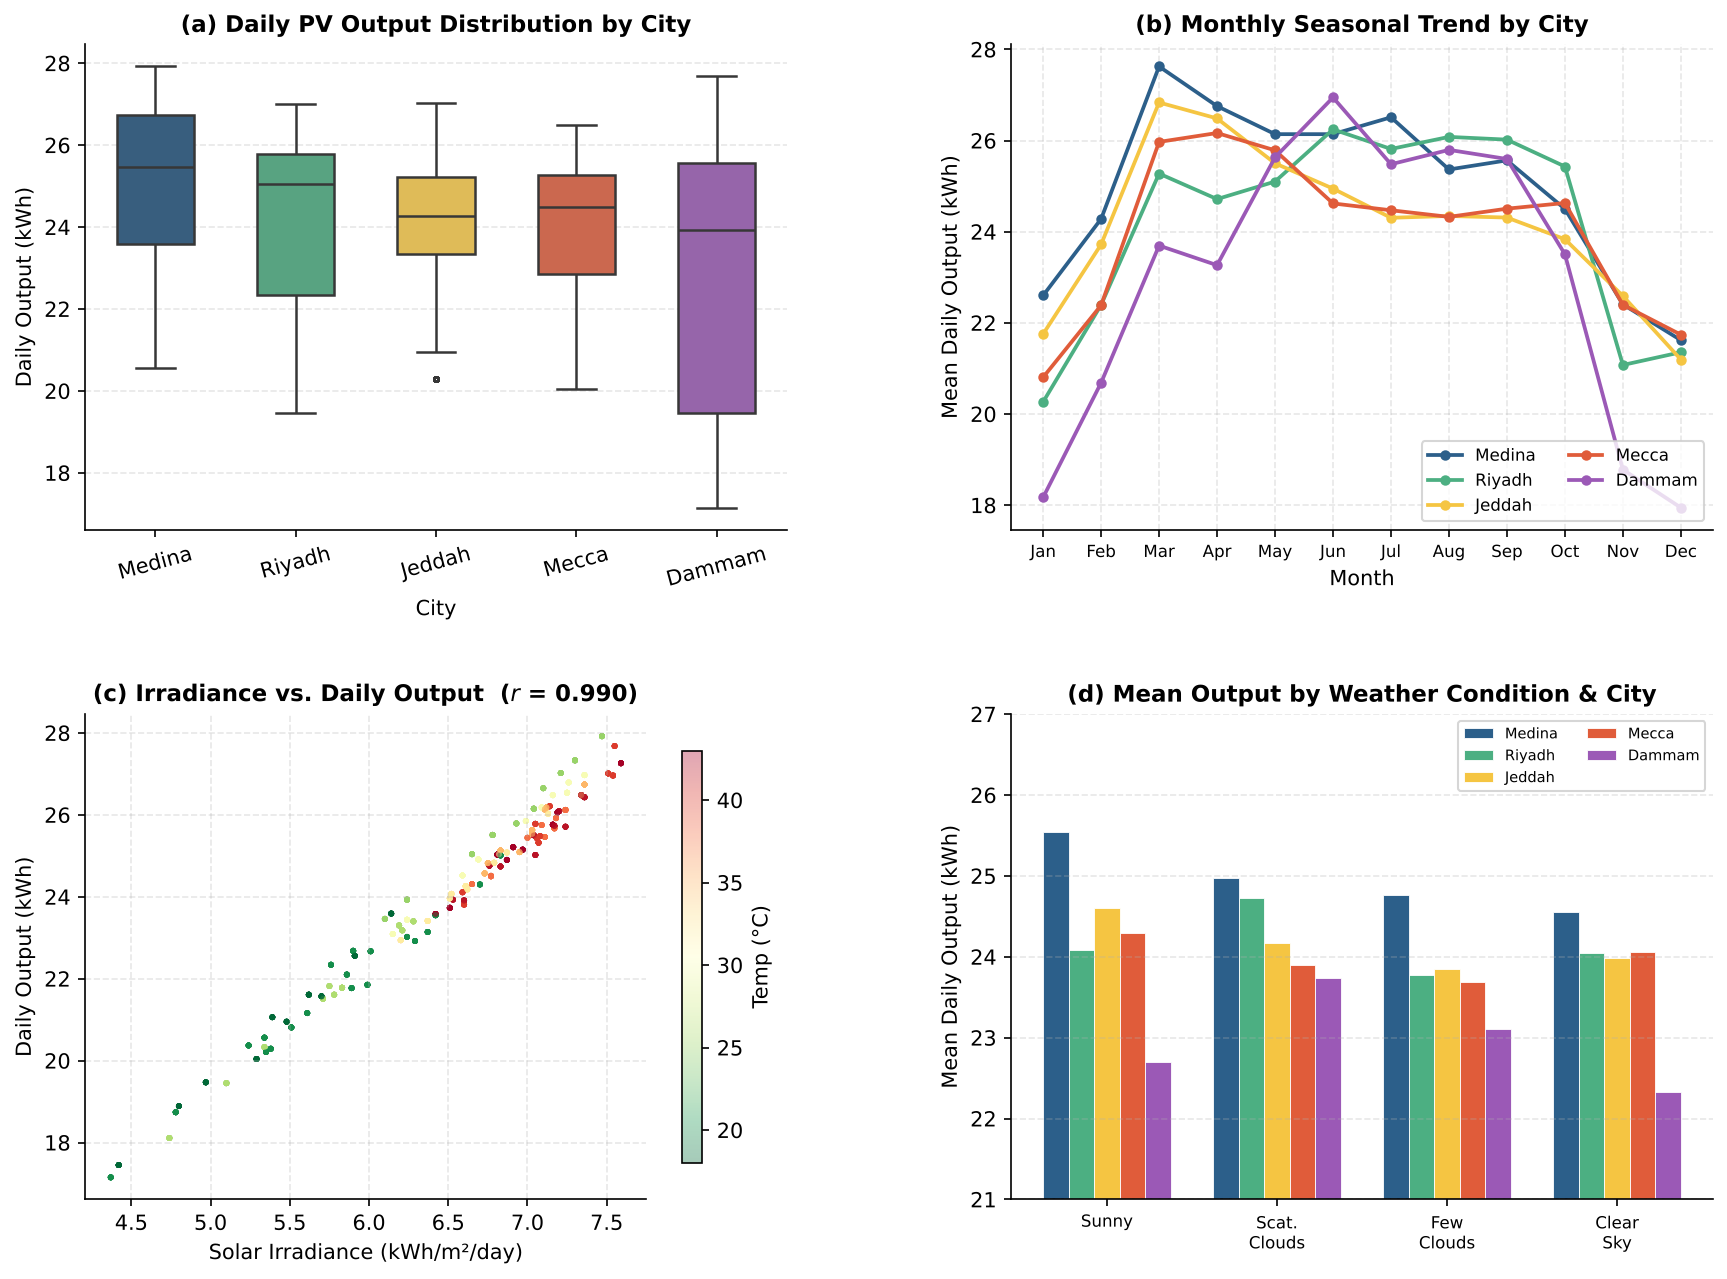

Saved: fig0_eda_overview.png


In [15]:
# Saves: fig0_eda_overview.png

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import pandas as pd

matplotlib.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'figure.dpi': 150,
    'savefig.dpi': 300, 'savefig.bbox': 'tight'
})

city_order   = ['Medina', 'Riyadh', 'Jeddah', 'Mecca', 'Dammam']
city_palette = ['#2C5F8A','#4CAF82','#F5C542','#E05C3A','#9B59B6']

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.32)

# ── (a) Box plot: daily output by city ───────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
sns.boxplot(
    data=df, x='City', y='Estimated_Daily_Output_kWh',
    order=city_order, palette=city_palette,
    width=0.55, linewidth=1.2, fliersize=2, ax=ax1
)
ax1.set_xlabel('City')
ax1.set_ylabel('Daily Output (kWh)')
ax1.set_title('(a) Daily PV Output Distribution by City')
ax1.spines[['top','right']].set_visible(False)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.tick_params(axis='x', rotation=15)

# ── (b) Monthly mean output ───────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
monthly = (df.groupby(['Month', 'City'])['Estimated_Daily_Output_kWh']
             .mean().reset_index())
for city, col in zip(city_order, city_palette):
    sub = monthly[monthly['City'] == city].sort_values('Month')
    ax2.plot(sub['Month'], sub['Estimated_Daily_Output_kWh'],
             marker='o', markersize=4, color=col, linewidth=1.8, label=city)
ax2.set_xlabel('Month')
ax2.set_ylabel('Mean Daily Output (kWh)')
ax2.set_title('(b) Monthly Seasonal Trend by City')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                     'Jul','Aug','Sep','Oct','Nov','Dec'], fontsize=8)
ax2.legend(fontsize=8, loc='lower right', ncol=2)
ax2.spines[['top','right']].set_visible(False)
ax2.grid(alpha=0.3, linestyle='--')

# ── (c) Irradiance vs daily output scatter ───────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
sample = df.sample(min(3000, len(df)), random_state=42)
sc = ax3.scatter(
    sample['Solar_Irradiance_kWh_m²_day'],
    sample['Estimated_Daily_Output_kWh'],
    c=sample['Temperature_°C'], cmap='RdYlGn_r',
    alpha=0.35, s=8, edgecolors='none'
)
plt.colorbar(sc, ax=ax3, label='Temp (°C)', shrink=0.85)
r = df['Solar_Irradiance_kWh_m²_day'].corr(df['Estimated_Daily_Output_kWh'])
ax3.set_xlabel('Solar Irradiance (kWh/m²/day)')
ax3.set_ylabel('Daily Output (kWh)')
ax3.set_title(f'(c) Irradiance vs. Daily Output  ($r$ = {r:.3f})')
ax3.spines[['top','right']].set_visible(False)
ax3.grid(alpha=0.3, linestyle='--')

# ── (d) Mean output by weather condition × city ──────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
weather_order = ['sunny', 'scattered clouds', 'few clouds', 'clear sky']
weather_city = (df.groupby(['Weather', 'City'])['Estimated_Daily_Output_kWh']
                  .mean().reset_index())
x      = np.arange(len(weather_order))
width  = 0.15
for j, (city, col) in enumerate(zip(city_order, city_palette)):
    sub = (weather_city[weather_city['City'] == city]
           .set_index('Weather')['Estimated_Daily_Output_kWh'])
    vals = [sub.get(w, np.nan) for w in weather_order]
    ax4.bar(x + j*width, vals, width, label=city, color=col,
            edgecolor='white', linewidth=0.4)
ax4.set_xticks(x + width*2)
ax4.set_xticklabels(['Sunny','Scat.\nClouds','Few\nClouds','Clear\nSky'],
                    fontsize=8)
ax4.set_ylabel('Mean Daily Output (kWh)')
ax4.set_title('(d) Mean Output by Weather Condition & City')
ax4.legend(fontsize=7, loc='upper right', ncol=2)
ax4.spines[['top','right']].set_visible(False)
ax4.grid(axis='y', alpha=0.3, linestyle='--')
ax4.set_ylim(21, 27)


plt.savefig('fig0_eda_overview.png', bbox_inches='tight')
plt.show()
print('Saved: fig0_eda_overview.png')

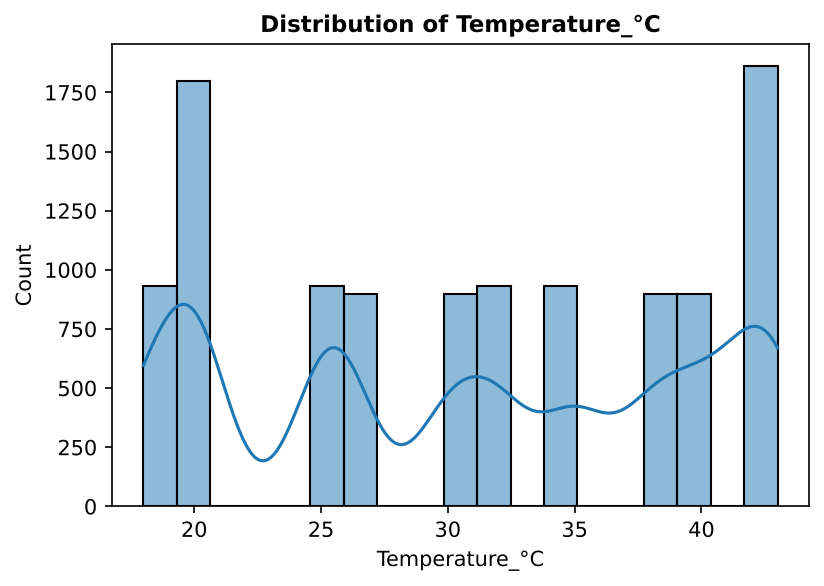

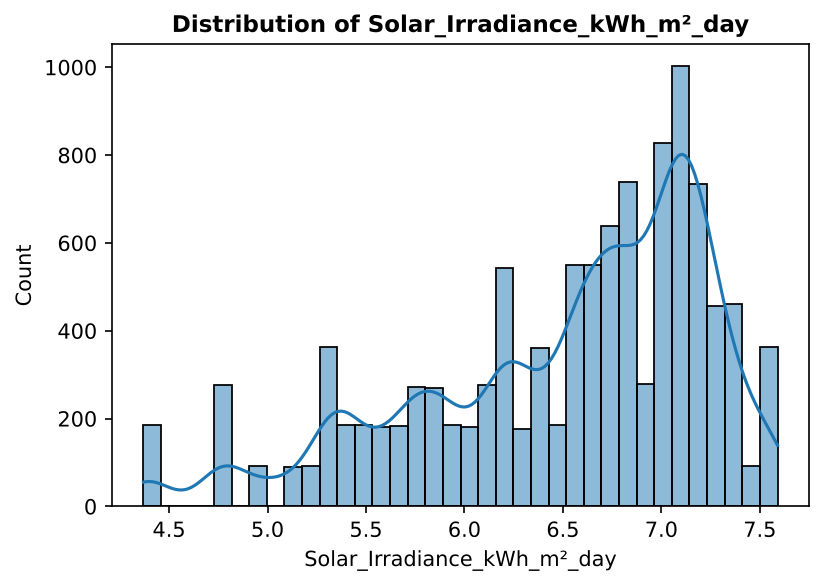

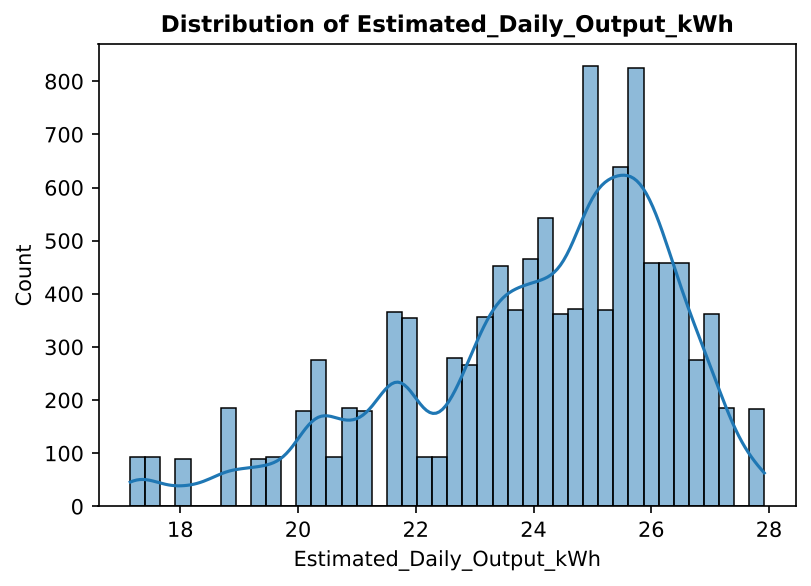

In [16]:
# ---------- Distribution Analysis ----------

numeric_cols = [
    'Temperature_°C',
    'Solar_Irradiance_kWh_m²_day',
    'Estimated_Daily_Output_kWh'
]

for col in numeric_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f'Distribution of {col}')

    plt.show()

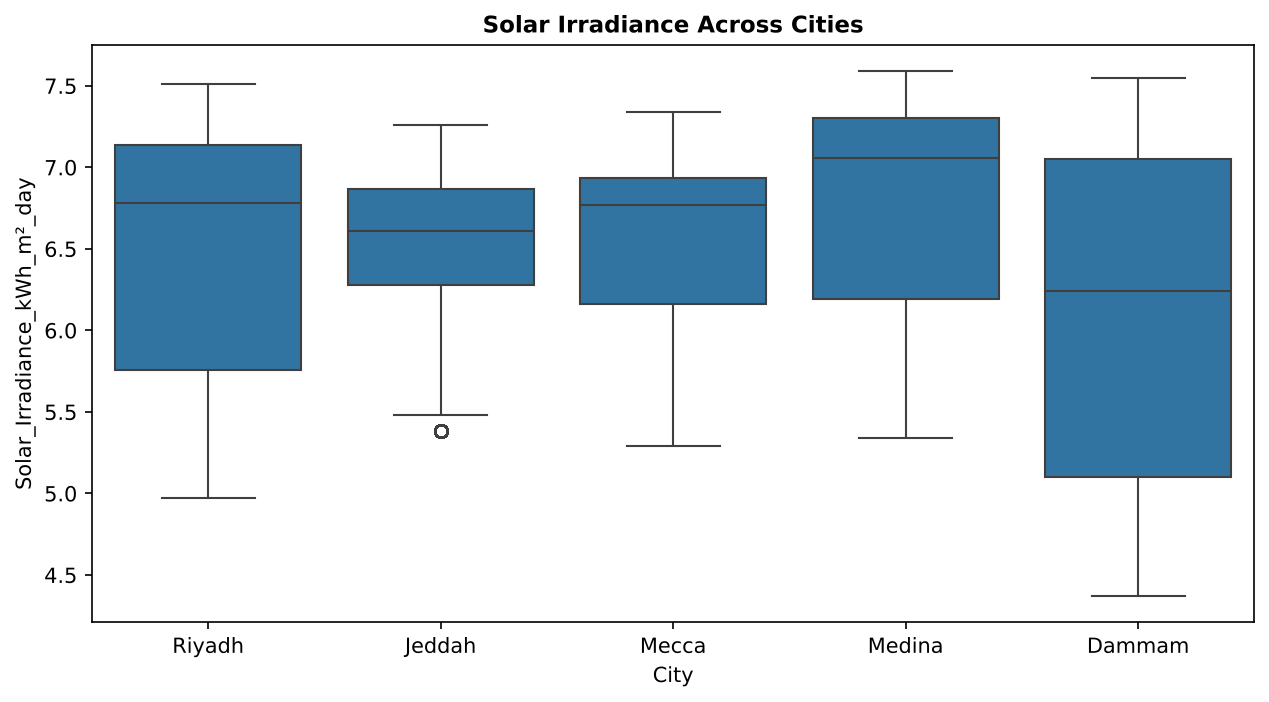

In [17]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='City',
    y='Solar_Irradiance_kWh_m²_day'
)

plt.title("Solar Irradiance Across Cities")
plt.show()

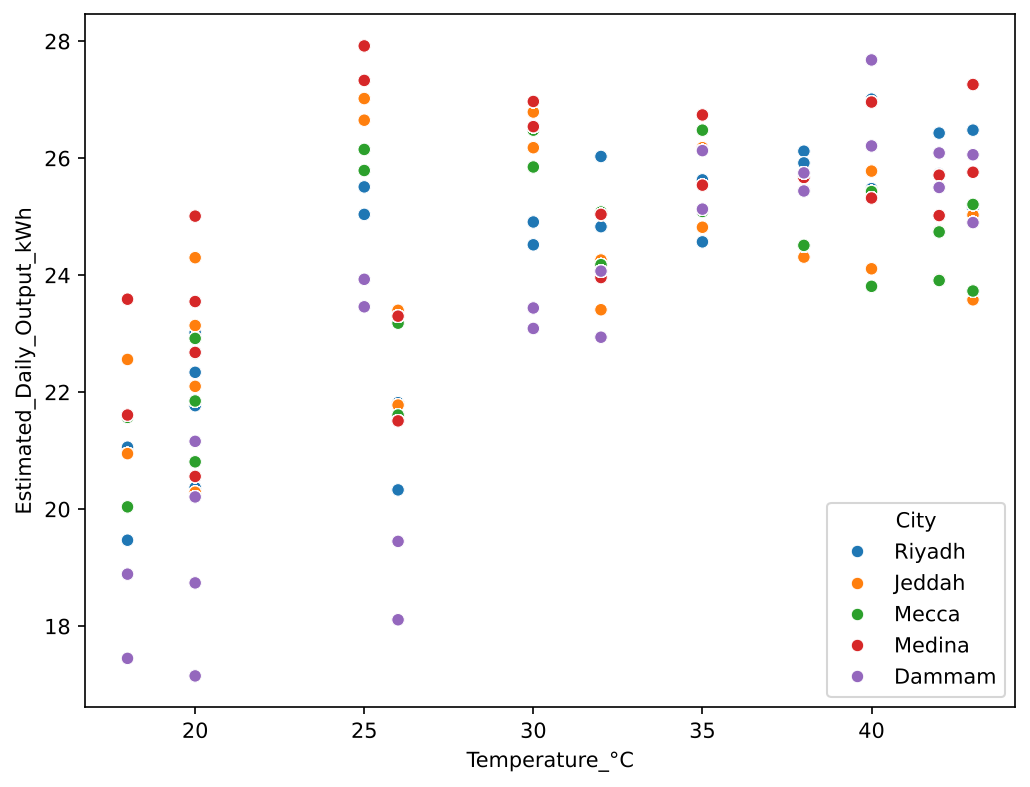

In [18]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x='Temperature_°C',
    y='Estimated_Daily_Output_kWh',
    hue='City'
)

plt.show()

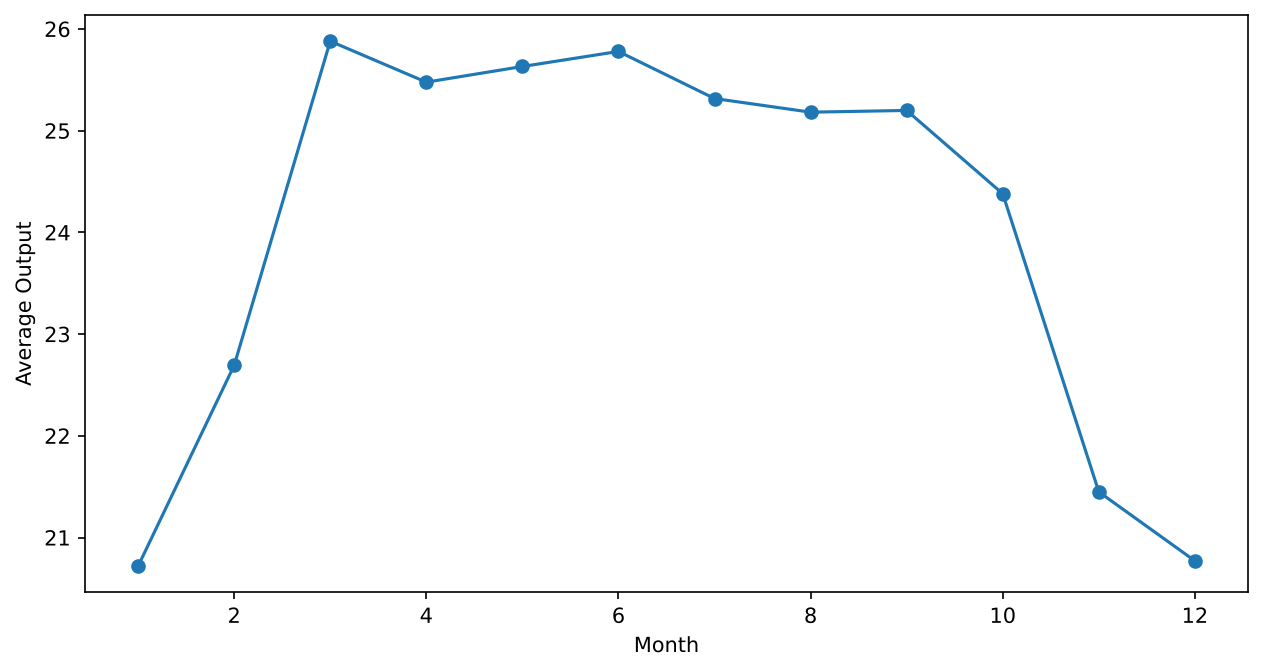

In [19]:
monthly=df.groupby(
    'Month'
)['Estimated_Daily_Output_kWh'].mean()

monthly.plot(
    kind='line',
    marker='o',
    figsize=(10,5)
)

plt.ylabel("Average Output")
plt.show()

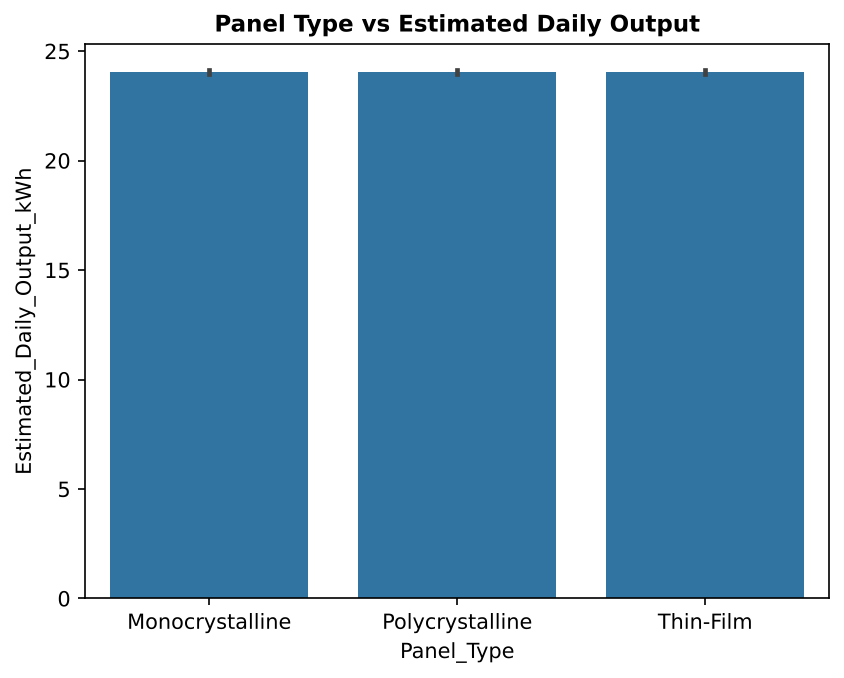

In [20]:
sns.barplot(
    data=df,
    x='Panel_Type',
    y='Estimated_Daily_Output_kWh'
)
plt.title(
'Panel Type vs Estimated Daily Output'
)

plt.show()

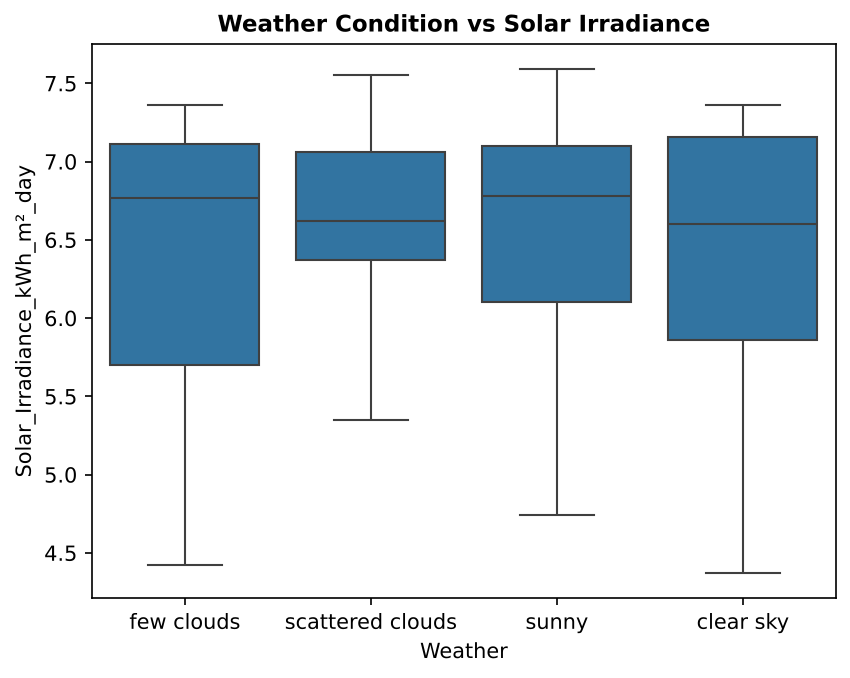

In [21]:
sns.boxplot(
    data=df,
    x='Weather',
    y='Solar_Irradiance_kWh_m²_day'
)
plt.title(
'Weather Condition vs Solar Irradiance'
)

plt.show()

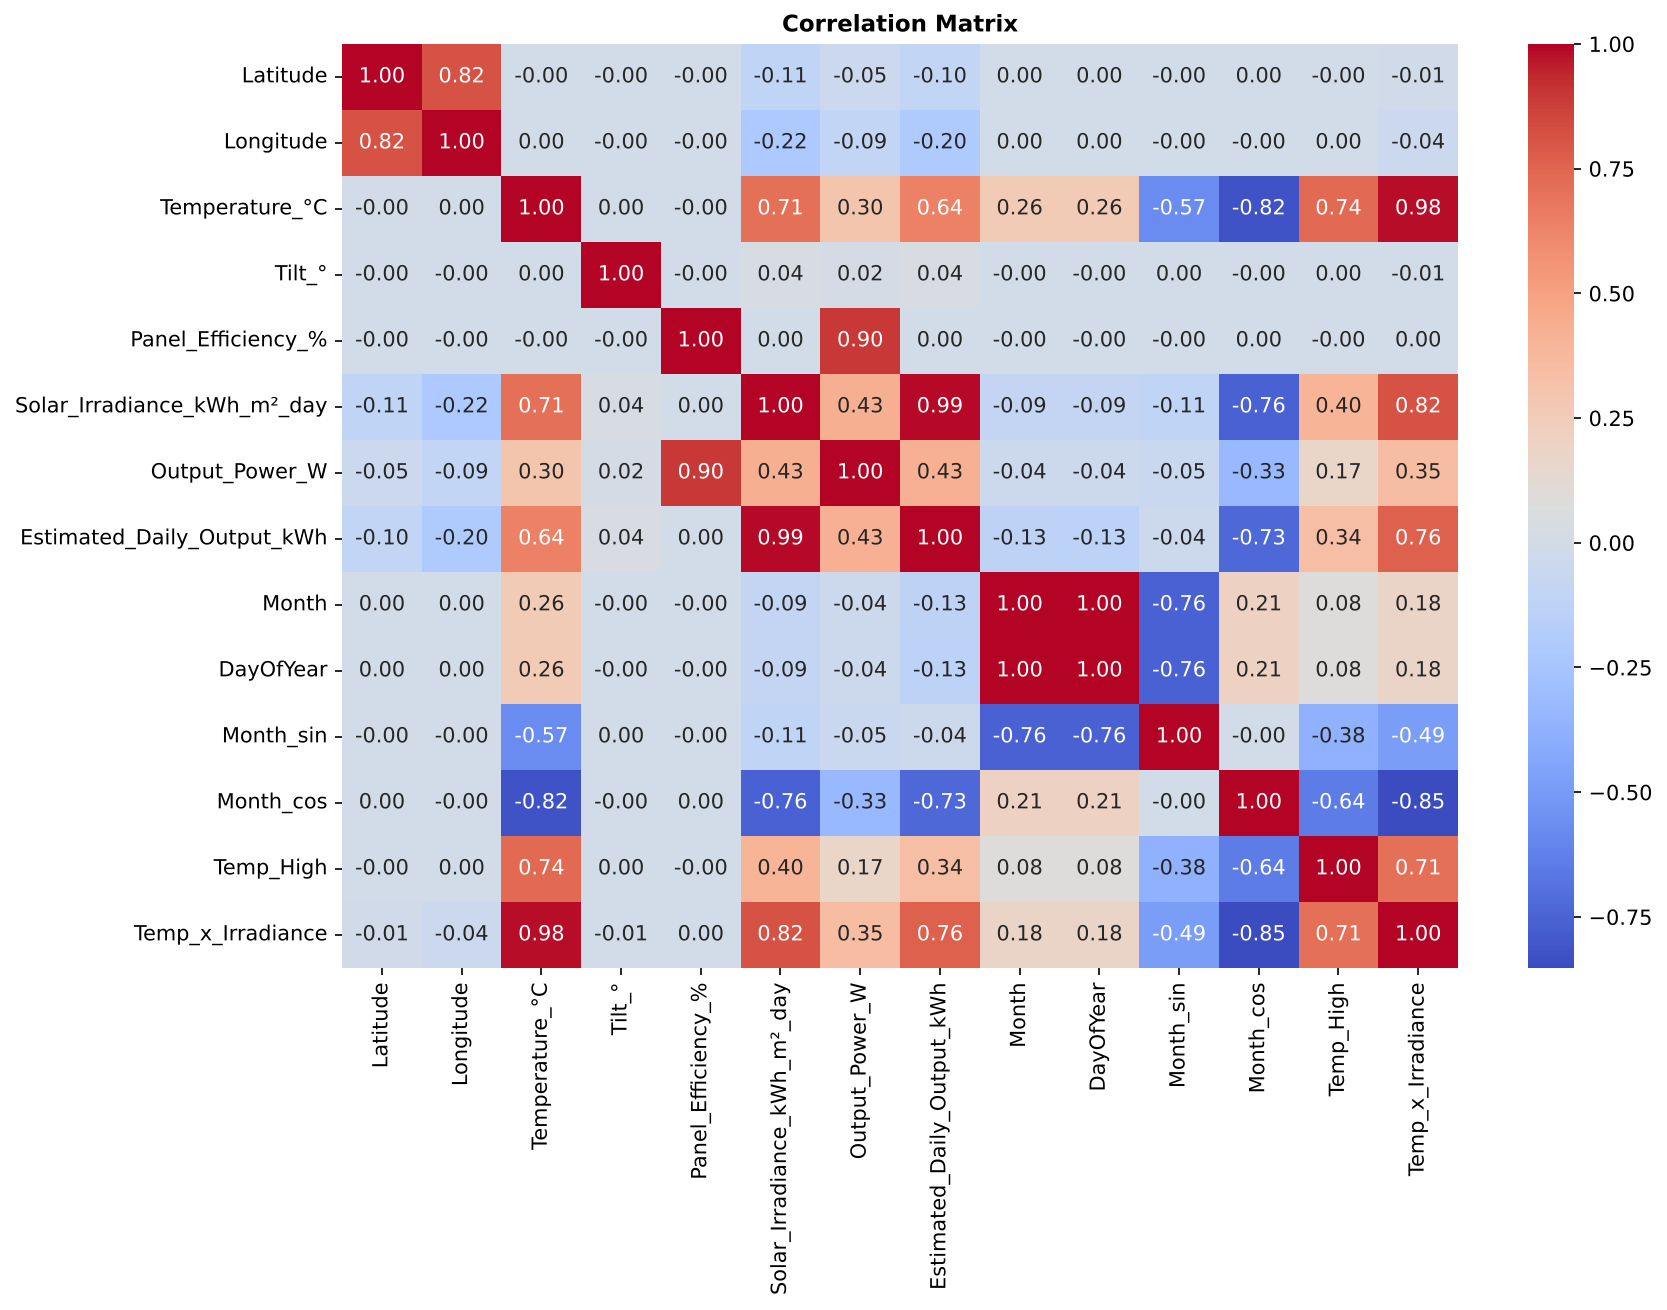

In [22]:
numeric=df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title(
'Correlation Matrix'
)

plt.show()

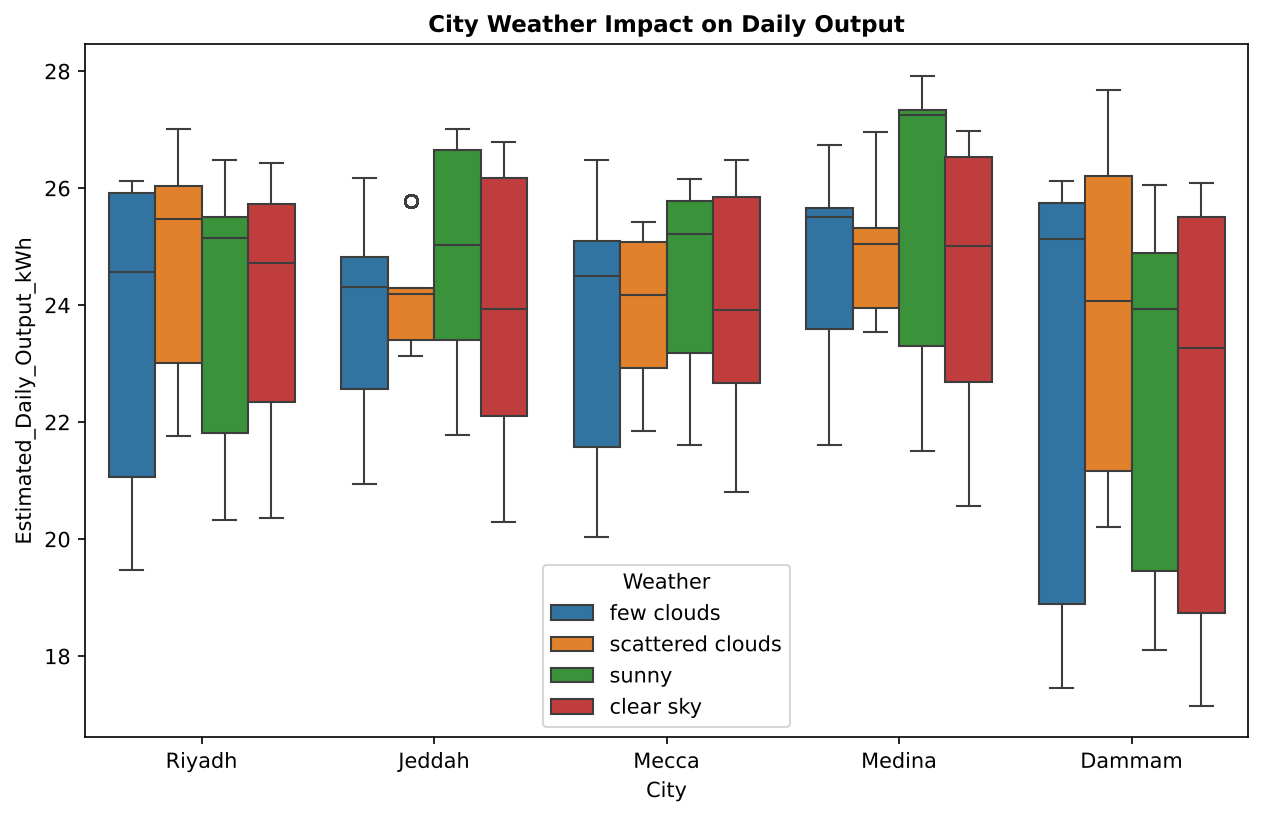

In [23]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x='City',
    y='Estimated_Daily_Output_kWh',
    hue='Weather'
)

plt.title(
'City Weather Impact on Daily Output'
)

plt.show()

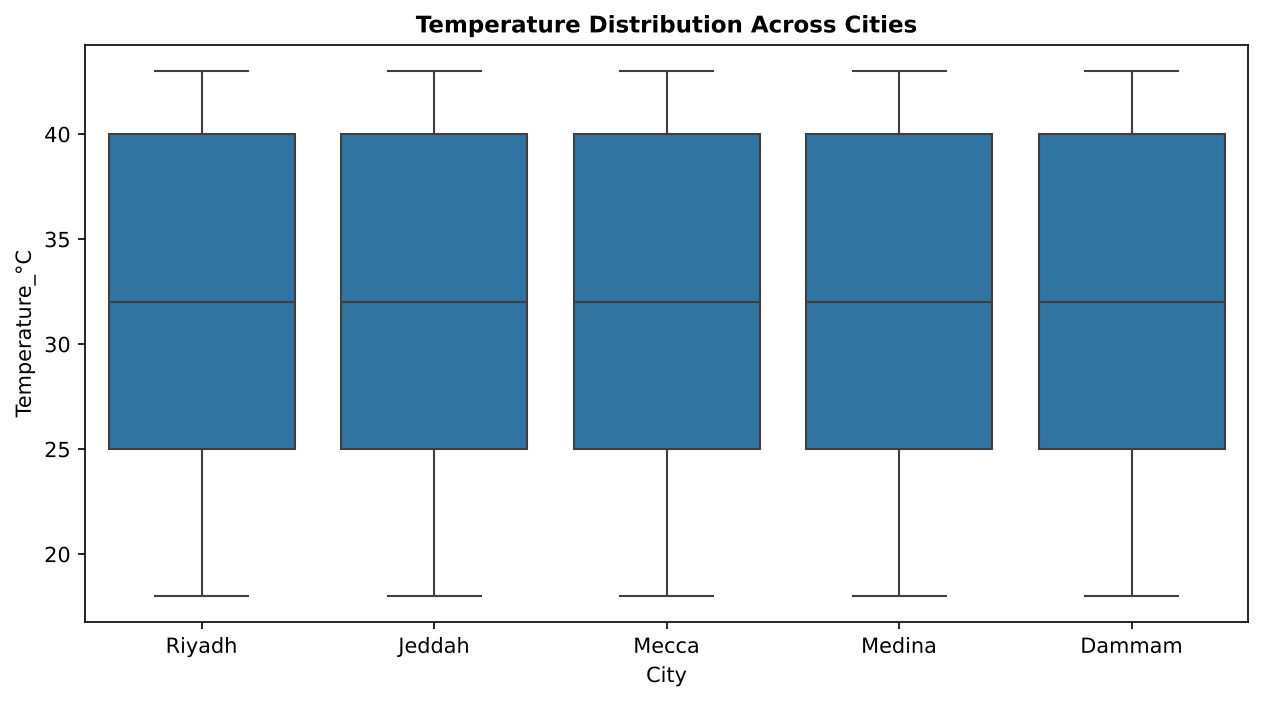

In [24]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='City',
    y='Temperature_°C'
)

plt.title(
    'Temperature Distribution Across Cities'
)

plt.show()

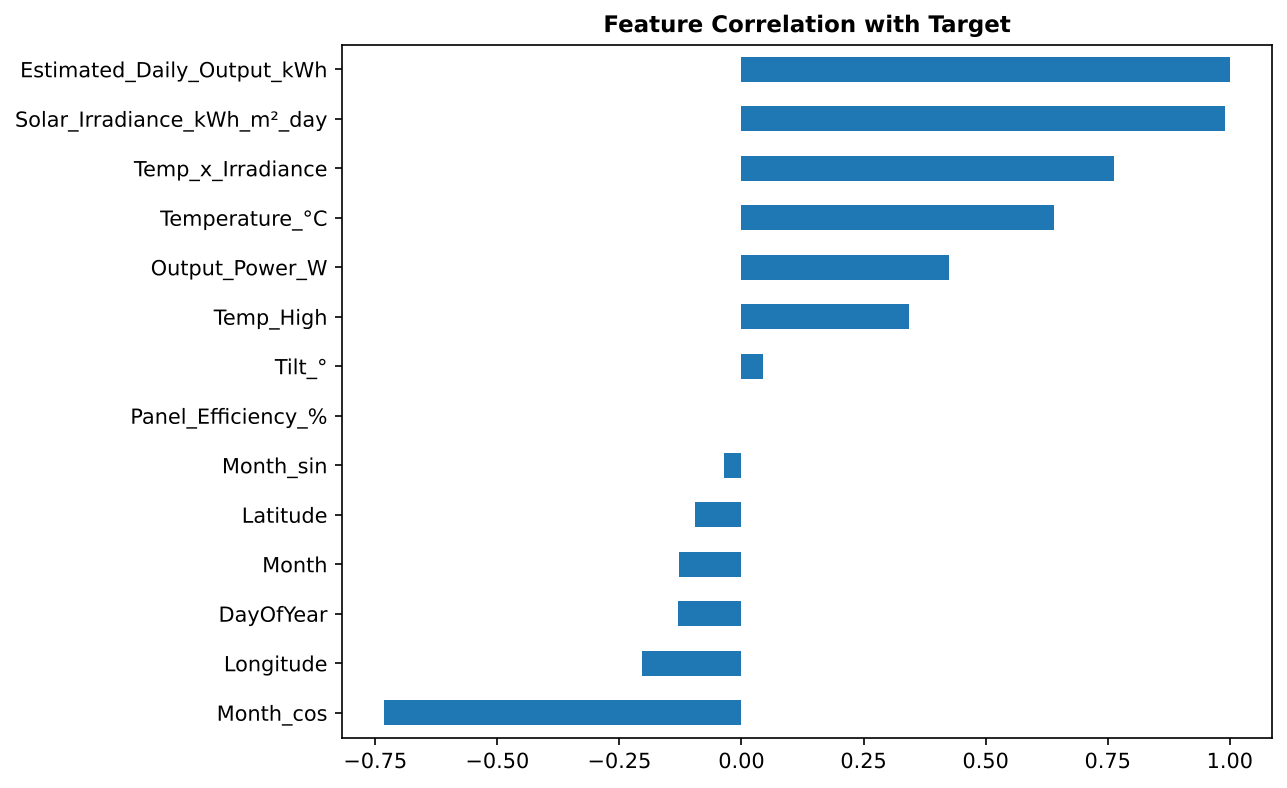

In [25]:
# ---------- Target Correlation Analysis ----------

target_corr=numeric.corr()[
'Estimated_Daily_Output_kWh'
].sort_values()

plt.figure(figsize=(8,6))

target_corr.plot(
kind='barh'
)

plt.title(
'Feature Correlation with Target'
)

plt.show()

In [26]:
# ---------- Top Predictive Features ----------

top_features = target_corr.abs().sort_values(
    ascending=False
)

print(
"\nMost Influential Features:"
)

print(top_features.head(10))


Most Influential Features:
Estimated_Daily_Output_kWh     1.000000
Solar_Irradiance_kWh_m²_day    0.989557
Temp_x_Irradiance              0.762094
Month_cos                      0.731404
Temperature_°C                 0.639209
Output_Power_W                 0.425398
Temp_High                      0.344002
Longitude                      0.204679
DayOfYear                      0.129510
Month                          0.128072
Name: Estimated_Daily_Output_kWh, dtype: float64


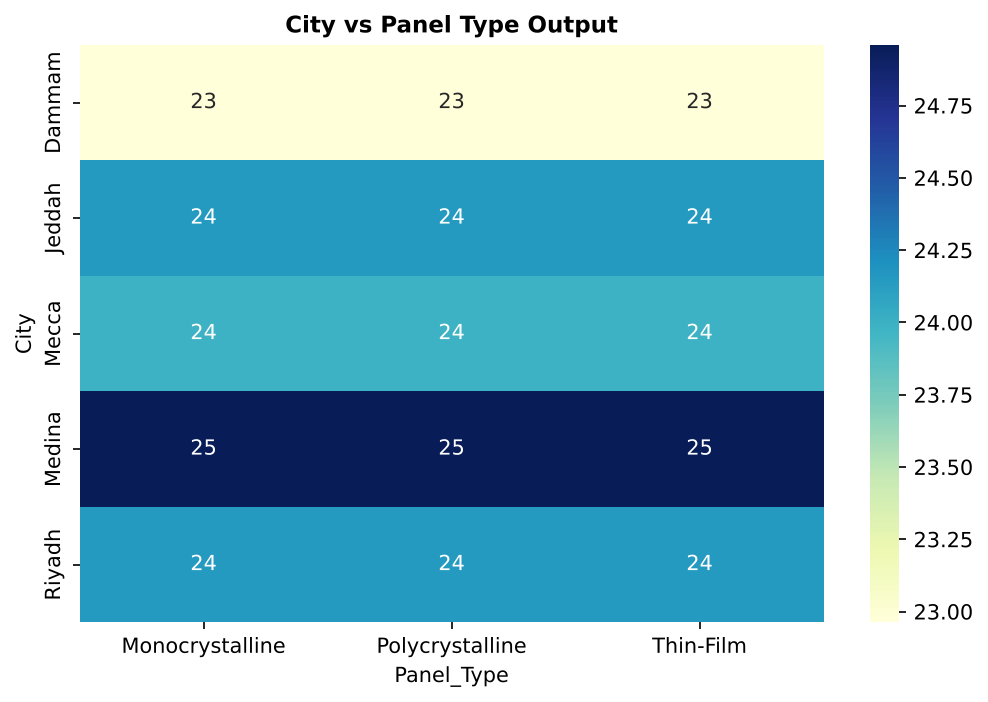

In [27]:
pivot=df.pivot_table(
    values='Estimated_Daily_Output_kWh',
    index='City',
    columns='Panel_Type',
    aggfunc='mean'
)

plt.figure(figsize=(8,5))

sns.heatmap(
    pivot,
    annot=True,
    cmap='YlGnBu'
)

plt.title(
    'City vs Panel Type Output'
)

plt.show()

In [28]:
df.groupby(
    'Panel_Type'
)['Estimated_Daily_Output_kWh'].describe()

,count,mean,std,min,25%,50%,75%,max
Panel_Type,,,,,,,,
Monocrystalline,3660.0,24.042257,2.324129,17.15,22.86,24.57,25.76,27.92
Polycrystalline,3660.0,24.042257,2.324129,17.15,22.86,24.57,25.76,27.92
Thin-Film,3660.0,24.042257,2.324129,17.15,22.86,24.57,25.76,27.92


In [29]:
# ---------- Panel Efficiency Validation ----------

print(

df.groupby(
'Panel_Efficiency_%'
)[
'Estimated_Daily_Output_kWh'
].mean()

)

Panel_Efficiency_%
12    24.042257
18    24.042257
22    24.042257
Name: Estimated_Daily_Output_kWh, dtype: float64


In [30]:
print(
"Panel efficiency levels show nearly identical output averages."
)

print(
"This suggests either balanced synthetic generation patterns "
"or limited efficiency influence within the current dataset."
)

Panel efficiency levels show nearly identical output averages.
This suggests either balanced synthetic generation patterns or limited efficiency influence within the current dataset.


In [31]:
df.groupby(
    'Mount_Type'
)['Estimated_Daily_Output_kWh'].mean()

Mount_Type
Ground     23.939781
Rooftop    24.144732
Name: Estimated_Daily_Output_kWh, dtype: float64

In [32]:
high_temp_analysis = df.groupby(
'Temp_High'
)[
'Estimated_Daily_Output_kWh'
].mean()

print(high_temp_analysis)

Temp_High
0    23.579044
1    25.421826
Name: Estimated_Daily_Output_kWh, dtype: float64


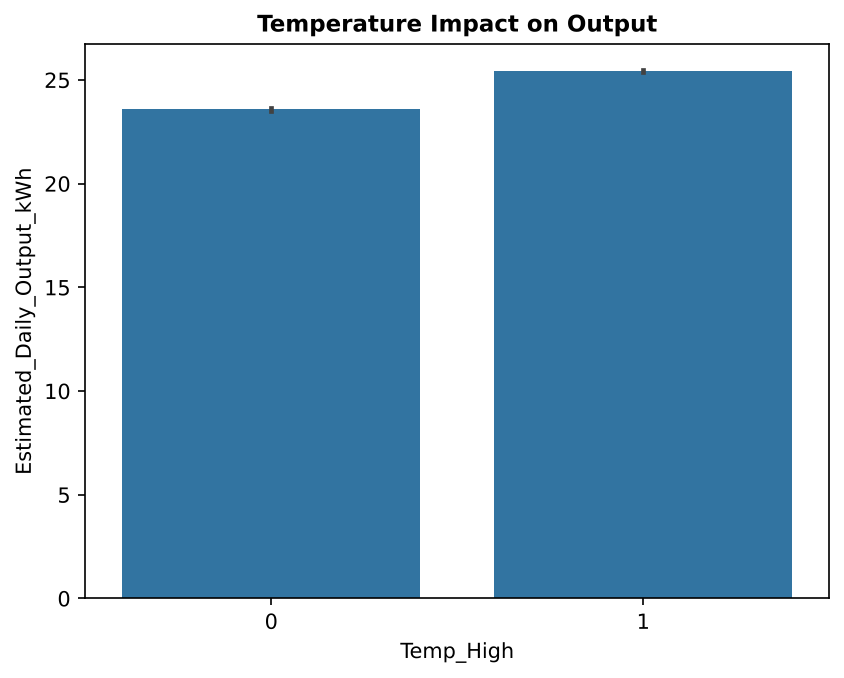

In [33]:
sns.barplot(
    data=df,
    x='Temp_High',
    y='Estimated_Daily_Output_kWh'
)

plt.title(
'Temperature Impact on Output'
)

plt.show()

In [34]:
print(
    "\nObservation:"
)

print(
    "Similar output values across panel types may indicate "
    "balanced synthetic patterns or limited efficiency variation."
)


Observation:
Similar output values across panel types may indicate balanced synthetic patterns or limited efficiency variation.


## Turn 2 — Preprocessing (revised for MMAI 2026)
**Revision notes (fixes applied in this version):**
1. One shared, date-sorted frame and one 80/20 chronological split — every model is evaluated on the *same* 2,196 test rows.
2. `Output_Power_W` removed from the inputs (it is a simulation output, not available at forecast time).
3. All scalers are fitted on training rows only.
4. Deep-learning windows now include the target day's exogenous inputs (days t−13 … t), so classical and deep models use the same information set.
5. Deep-learning validation = the chronologically last 10% of training dates (previously the last 20% of *groups*).
6. Deep-learning predictions are mapped back to row indices, so figures and Diebold–Mariano tests compare aligned errors.

In [35]:
import os, random, warnings
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
matplotlib.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,
    'axes.titleweight':'bold','axes.labelsize':11,'figure.dpi':150,'savefig.dpi':300,'savefig.bbox':'tight'})

SEED = 42
np.random.seed(SEED); random.seed(SEED)
target_col = 'Estimated_Daily_Output_kWh'
TEMP = [c for c in df.columns if c.startswith('Temperature')][0]
IRR  = [c for c in df.columns if c.startswith('Solar_Irradiance')][0]

# Shared base frame: stable date sort -> identical row order for every model
base = df.copy()
base['Date'] = pd.to_datetime(base['Date'])
base = base.sort_values('Date', kind='stable').reset_index(drop=True)
base['DayOfYear_sin'] = np.sin(2*np.pi*base['DayOfYear']/366)
base['DayOfYear_cos'] = np.cos(2*np.pi*base['DayOfYear']/366)

split_index = int(len(base)*0.80)
train_idx = np.arange(split_index); test_idx = np.arange(split_index, len(base))
print(f'Train rows: {len(train_idx)} | Test rows: {len(test_idx)}')
print('Test period:', base.loc[split_index,'Date'].date(), '->', base['Date'].max().date())
print(f"Train mean output {base.loc[train_idx,target_col].mean():.2f} kWh | Test mean {base.loc[test_idx,target_col].mean():.2f} kWh")

# Data-generation checks reported in the paper
dup = (base.groupby(['Date','City','Mount_Type'])[target_col].nunique()==1).mean()
same_temp = (base.groupby('Date')[TEMP].nunique()==1).mean()
print(f'Output identical across the 3 panel types (same city/date/mount): {dup:.0%}')
print(f'Same temperature in all 5 cities on a given day: {same_temp:.0%}')
print('Unique targets:', base.drop_duplicates(['Date','City','Mount_Type']).shape[0])
base['Month_'] = base['Date'].dt.month
print('Distinct output values in the whole dataset:', base[target_col].nunique())
print('Output constant within each City x Month x Mount cell:',
      (base.groupby(['City','Month_','Mount_Type'])[target_col].nunique()==1).mean() == 1.0)
print('Weather constant within each City x Month:', (base.groupby(['City','Month_'])['Weather'].nunique()==1).mean() == 1.0)
print('One temperature value per month (shared by all cities):', (base.groupby('Month_')[TEMP].nunique()==1).mean() == 1.0)
print('Distinct City x Month x Mount cells in the test set:',
      base.loc[split_index:].groupby(['City','Month_','Mount_Type']).ngroups)
base = base.drop(columns='Month_')

Train rows: 8784 | Test rows: 2196
Test period: 2024-10-19 -> 2024-12-31
Train mean output 24.64 kWh | Test mean 21.65 kWh
Output identical across the 3 panel types (same city/date/mount): 100%
Same temperature in all 5 cities on a given day: 100%
Unique targets: 3660
Distinct output values in the whole dataset: 113
Output constant within each City x Month x Mount cell: True
Weather constant within each City x Month: True
One temperature value per month (shared by all cities): True
Distinct City x Month x Mount cells in the test set: 30


In [36]:
# Feature matrix shared by the classical models
DROP = ['Date', target_col, 'Output_Power_W']      # Output_Power_W excluded (simulation output)
cat_cols = ['City','Weather','Panel_Type','Mount_Type']
feat = pd.get_dummies(base.drop(columns=DROP), columns=cat_cols, drop_first=True).astype(float)
feature_names = feat.columns.tolist()
print(f'{len(feature_names)} classical features:', feature_names)

from sklearn.preprocessing import MinMaxScaler
X_train = feat.iloc[train_idx].copy(); X_test = feat.iloc[test_idx].copy()
y_train = base.loc[train_idx, target_col].values; y_test = base.loc[test_idx, target_col].values
scaler = MinMaxScaler().fit(X_train)                 # fitted on training rows only
X_train[:] = scaler.transform(X_train); X_test[:] = scaler.transform(X_test)

24 classical features: ['Latitude', 'Longitude', 'Temperature_°C', 'Tilt_°', 'Panel_Efficiency_%', 'Solar_Irradiance_kWh_m²_day', 'Month', 'DayOfYear', 'Month_sin', 'Month_cos', 'Temp_High', 'Temp_x_Irradiance', 'DayOfYear_sin', 'DayOfYear_cos', 'City_Jeddah', 'City_Mecca', 'City_Medina', 'City_Riyadh', 'Weather_few clouds', 'Weather_scattered clouds', 'Weather_sunny', 'Panel_Type_Polycrystalline', 'Panel_Type_Thin-Film', 'Mount_Type_Rooftop']


## Turn 3 — Classical baselines

In [38]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

def metrics(name, y, p):
    return {'Model':name,'RMSE':float(np.sqrt(mean_squared_error(y,p))),'MAE':float(mean_absolute_error(y,p)),
            'MAPE(%)':float(np.mean(np.abs((y-p)/y))*100),'R2':float(r2_score(y,p)),'MBE':float(np.mean(p-y))}

classical = {
    'Mean Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, random_state=SEED),
    'XGBoost': xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                                colsample_bytree=0.8, reg_alpha=0.1, random_state=SEED, n_jobs=-1, verbosity=0),
}
preds, rows = {}, []          # preds[name] = array aligned with test_idx
for name, mdl in classical.items():
    mdl.fit(X_train, y_train); p = mdl.predict(X_test)
    preds[name] = p; rows.append({**metrics(name, y_test, p), 'Category':'ML Baseline'})
xgb_model = classical['XGBoost']
print(pd.DataFrame(rows).sort_values('RMSE').round(4).to_string(index=False))

            Model   RMSE    MAE  MAPE(%)      R2    MBE    Category
          XGBoost 0.4499 0.3818   1.8276  0.9498 0.1172 ML Baseline
    Decision Tree 0.4527 0.3623   1.7253  0.9492 0.0285 ML Baseline
Gradient Boosting 0.4820 0.3273   1.6313  0.9424 0.1012 ML Baseline
    Random Forest 0.5931 0.4557   2.2188  0.9127 0.1492 ML Baseline
Linear Regression 2.7742 2.4667  11.8481 -0.9093 2.4544 ML Baseline
    Mean Baseline 3.6039 3.0721  15.1669 -2.2221 2.9928 ML Baseline


## Turn 4 — Deep learning (aligned, same information set)

In [39]:
import tensorflow as tf
from tensorflow.keras import layers, callbacks, Model, Input
tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass

WINDOW, EPOCHS, BATCH = 14, 120, 32
group_cols = ['City','Panel_Type','Mount_Type']
dl_feat = pd.get_dummies(base.drop(columns=DROP), columns=cat_cols, drop_first=False).astype(float)
dl_cols = dl_feat.columns.tolist()
fs = MinMaxScaler().fit(dl_feat.iloc[train_idx]); ts = MinMaxScaler().fit(base.loc[train_idx,[target_col]])
dl_X = fs.transform(dl_feat).astype(np.float32)
dl_y = ts.transform(base[[target_col]]).ravel().astype(np.float32)

def make_windows(window):
    Xs, ys, idx = [], [], []
    for _, g in base.groupby(group_cols, sort=False):
        ii = g.index.to_numpy()                       # already date-ordered
        for k in range(window-1, len(ii)):            # window = days t-13 ... t (includes target day inputs)
            Xs.append(dl_X[ii[k-window+1:k+1]]); ys.append(dl_y[ii[k]]); idx.append(ii[k])
    Xs, ys, idx = np.asarray(Xs), np.asarray(ys), np.asarray(idx)
    o = np.argsort(idx, kind='stable')                # chronological order
    return Xs[o], ys[o], idx[o]

Xw, yw, iw = make_windows(WINDOW)
tr_m, te_m = iw < split_index, iw >= split_index
Xtr_all, ytr_all, Xte_seq, yte_seq, te_rows = Xw[tr_m], yw[tr_m], Xw[te_m], yw[te_m], iw[te_m]
assert np.array_equal(te_rows, test_idx), 'deep-learning test rows must match classical test rows'
v = int(len(Xtr_all)*0.90)                            # last 10% of training dates -> validation
Xtr_seq, ytr_seq, Xva_seq, yva_seq = Xtr_all[:v], ytr_all[:v], Xtr_all[v:], ytr_all[v:]
n_t, n_f = Xtr_seq.shape[1], Xtr_seq.shape[2]
print(f'Windows: train {len(Xtr_seq)}, val {len(Xva_seq)}, test {len(Xte_seq)} | shape ({n_t}, {n_f})')

def inv(v): return ts.inverse_transform(np.asarray(v).reshape(-1,1)).ravel()

I0000 00:00:1792877921.794700    2886 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792877923.296422    2886 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Windows: train 7554, val 840, test 2196 | shape (14, 28)


In [40]:
def compile_(m, lr=1e-3):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse', metrics=['mae']); return m

def build_dense(nf):
    i = Input((nf,)); x = layers.Dense(128,activation='relu')(i); x = layers.Dropout(0.2)(x)
    x = layers.Dense(64,activation='relu')(x); x = layers.Dropout(0.15)(x)
    return compile_(Model(i, layers.Dense(1)(x), name='Dense_NN'))
def build_rnn(cell, nt, nf, name, bi=False, units=96):
    i = Input((nt,nf)); r = cell(units if not bi else 64)
    x = layers.Bidirectional(r)(i) if bi else r(i)
    x = layers.Dropout(0.2)(x); x = layers.Dense(48,activation='relu')(x)
    return compile_(Model(i, layers.Dense(1)(x), name=name))
def enc_block(x, heads=4, key_dim=64, ff=128, drop=0.15):
    a = layers.MultiHeadAttention(num_heads=heads, key_dim=key_dim, dropout=drop)(x, x)
    x1 = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(drop)(a))
    f = layers.Conv1D(ff,1,activation='relu')(x1); f = layers.Dropout(drop)(f); f = layers.Conv1D(x1.shape[-1],1)(f)
    return layers.LayerNormalization(epsilon=1e-6)(x1 + f)
def build_transformer(nt, nf):
    i = Input((nt,nf)); x = enc_block(i); x = enc_block(x); x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64,activation='relu')(x); x = layers.Dropout(0.2)(x)
    return compile_(Model(i, layers.Dense(1)(x), name='Transformer_Encoder'))
def build_cnn_lstm(nt, nf):
    i = Input((nt,nf)); x = layers.Conv1D(64,3,padding='causal',activation='relu')(i)
    x = layers.MaxPooling1D(2)(x); x = layers.LSTM(80)(x); x = layers.Dropout(0.2)(x)
    x = layers.Dense(48,activation='relu')(x)
    return compile_(Model(i, layers.Dense(1)(x), name='CNN_LSTM'))
class PositionalEncoding(layers.Layer):
    def __init__(self, max_len, d_model, **kw):
        super().__init__(**kw)
        pos = np.arange(max_len)[:,None]; dim = np.arange(d_model)[None,:]
        ang = pos/np.power(10000, (2*(dim//2))/d_model)
        ang[:,0::2] = np.sin(ang[:,0::2]); ang[:,1::2] = np.cos(ang[:,1::2])
        self.pe = tf.constant(ang[None], tf.float32)
    def call(self, x): return x + self.pe[:, :tf.shape(x)[1], :]
def build_cnn_lstm_transformer(nt, nf):
    i = Input((nt,nf))
    x = layers.Conv1D(64,3,padding='causal',activation='relu')(i)
    x = layers.Conv1D(64,3,padding='causal',activation='relu')(x); x = layers.BatchNormalization()(x)
    x = layers.LSTM(96, return_sequences=True)(x); x = layers.Dropout(0.2)(x)
    x = PositionalEncoding(nt, 96)(x)
    x = enc_block(x, key_dim=24, ff=256); x = enc_block(x, key_dim=24, ff=256)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dense(64,activation='relu')(x); x = layers.Dropout(0.2)(x)
    return compile_(Model(i, layers.Dense(1)(x), name='CNN_LSTM_Transformer'))

deep_specs = {
    'Dense Neural Network': (lambda: build_dense(n_f), 'dense'),
    'LSTM':                 (lambda: build_rnn(layers.LSTM, n_t, n_f, 'LSTM'), 'seq'),
    'GRU':                  (lambda: build_rnn(layers.GRU,  n_t, n_f, 'GRU'), 'seq'),
    'Bi-GRU':               (lambda: build_rnn(layers.GRU,  n_t, n_f, 'BiGRU', bi=True), 'seq'),
    'Transformer Encoder':  (lambda: build_transformer(n_t, n_f), 'seq'),
    'CNN-LSTM Hybrid':      (lambda: build_cnn_lstm(n_t, n_f), 'seq'),
    'CNN-LSTM-Transformer': (lambda: build_cnn_lstm_transformer(n_t, n_f), 'seq'),
}
histories = {}
for name, (builder, kind) in deep_specs.items():
    tf.keras.utils.set_random_seed(SEED)
    m = builder()
    sel = (lambda a: a[:, -1, :]) if kind == 'dense' else (lambda a: a)   # dense NN sees day t only
    cb = [callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)]
    h = m.fit(sel(Xtr_seq), ytr_seq, validation_data=(sel(Xva_seq), yva_seq), epochs=EPOCHS,
              batch_size=BATCH, shuffle=True, callbacks=cb, verbose=0)
    histories[name] = h.history
    p = inv(m.predict(sel(Xte_seq), verbose=0).ravel())
    preds[name] = p
    r = metrics(name, y_test, p); r['Category'] = 'Proposed Model' if name=='CNN-LSTM-Transformer' else 'Deep Learning'
    r['Params'] = m.count_params(); r['Epochs'] = len(h.history['loss']); rows.append(r)
    print(f"{name:22s} RMSE {r['RMSE']:.4f}  R2 {r['R2']:.4f}  epochs {r['Epochs']}  params {r['Params']:,}")

Dense Neural Network   RMSE 2.6530  R2 -0.7461  epochs 16  params 12,033


LSTM                   RMSE 2.6466  R2 -0.7377  epochs 22  params 52,705


GRU                    RMSE 1.4766  R2 0.4591  epochs 30  params 40,993


Bi-GRU                 RMSE 1.1174  R2 0.6903  epochs 56  params 42,337


Transformer Encoder    RMSE 2.0870  R2 -0.0805  epochs 30  params 75,729


CNN-LSTM Hybrid        RMSE 2.0332  R2 -0.0255  epochs 23  params 55,777


CNN-LSTM-Transformer   RMSE 2.7441  R2 -0.8680  epochs 18  params 260,417


## Turn 5 — Comparison table, statistics and figures

In [41]:
master = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
master.insert(0, 'Rank', range(1, len(master)+1))
print(master[['Rank','Model','RMSE','MAE','MAPE(%)','R2','MBE']].round(4).to_string(index=False))
master.to_csv('t5_master_table.csv', index=False)
best_name = master.loc[0,'Model']; best_preds = preds[best_name]
y_true_all = y_test                                    # aligned with every entry of `preds`
for k, p in preds.items(): assert len(p) == len(y_true_all), k

 Rank                Model   RMSE    MAE  MAPE(%)      R2    MBE
    1              XGBoost 0.4499 0.3818   1.8276  0.9498 0.1172
    2        Decision Tree 0.4527 0.3623   1.7253  0.9492 0.0285
    3    Gradient Boosting 0.4820 0.3273   1.6313  0.9424 0.1012
    4        Random Forest 0.5931 0.4557   2.2188  0.9127 0.1492
    5               Bi-GRU 1.1174 0.8857   4.2202  0.6903 0.7471
    6                  GRU 1.4766 1.2096   5.7669  0.4591 1.1382
    7      CNN-LSTM Hybrid 2.0332 1.7908   8.6467 -0.0255 1.7081
    8  Transformer Encoder 2.0870 1.7487   8.5931 -0.0805 1.6526
    9                 LSTM 2.6466 2.4079  11.5783 -0.7377 2.3428
   10 Dense Neural Network 2.6530 2.2629  11.1181 -0.7461 2.1151
   11 CNN-LSTM-Transformer 2.7441 2.4103  11.7719 -0.8680 2.3230
   12    Linear Regression 2.7742 2.4667  11.8481 -0.9093 2.4544
   13        Mean Baseline 3.6039 3.0721  15.1669 -2.2221 2.9928


In [42]:
# Walk-forward CV (5 folds) on the date-ordered frame, scaler fitted inside each fold
from sklearn.model_selection import TimeSeriesSplit
cv_rows = []
oof = pd.Series(np.nan, index=base.index)             # out-of-fold XGBoost predictions (used for RQ4)
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(feat)):
    sc = MinMaxScaler().fit(feat.iloc[tr]); Xa, Xb = sc.transform(feat.iloc[tr]), sc.transform(feat.iloc[va])
    ya, yb = base[target_col].values[tr], base[target_col].values[va]
    for name, mdl in [('XGBoost', xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                          colsample_bytree=0.8, reg_alpha=0.1, random_state=SEED, n_jobs=-1, verbosity=0)),
                      ('Random Forest', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))]:
        p = mdl.fit(Xa, ya).predict(Xb)
        if name == 'XGBoost': oof.iloc[va] = p
        cv_rows.append({'Model':name,'Fold':fold+1,'RMSE':np.sqrt(mean_squared_error(yb,p)),'R2':r2_score(yb,p)})
cv_df = pd.DataFrame(cv_rows); cv_df.to_csv('t5_cv_results.csv', index=False)
print(cv_df.groupby('Model')[['RMSE','R2']].agg(['mean','std']).round(4))

                 RMSE              R2        
                 mean     std    mean     std
Model                                        
Random Forest  0.4911  0.1711  0.8236  0.0544
XGBoost        0.4174  0.1221  0.8661  0.0469


In [43]:
# Diebold-Mariano (HLN-corrected) + Wilcoxon on ALIGNED errors.
# Convention: d_t = e_best^2 - e_other^2 ; DM < 0  => best model has lower squared error.
from scipy import stats
def dm_test(e1, e2, h=1):
    d = e1**2 - e2**2; T = len(d); db = d.mean()
    gam = [np.var(d)] + [np.mean((d[:-k]-db)*(d[k:]-db)) for k in range(1, h)]
    var_d = (gam[0] + 2*sum(gam[1:]))/T
    dm = db/np.sqrt(var_d) * np.sqrt((T+1-2*h+h*(h-1)/T)/T)
    return dm, 2*(1-stats.t.cdf(abs(dm), df=T-1))
e_best = best_preds - y_true_all
stat_rows = []
for name, p in preds.items():
    if name == best_name: continue
    e = p - y_true_all; dm, pdm = dm_test(e_best, e)
    w_p = stats.wilcoxon(np.abs(e_best), np.abs(e), alternative='less').pvalue
    stat_rows.append({'Model':name,'DM stat':dm,'DM p':pdm,'Wilcoxon p':w_p,
                      'Better':best_name if dm < 0 else name,'Sig (Bonferroni)':(pdm < 0.05/(len(preds)-1))})
stat_df = pd.DataFrame(stat_rows).sort_values('DM stat'); stat_df.to_csv('t5_statistical_tests.csv', index=False)
print(f'{best_name} vs competitors (row level — overstates evidence, rows are repeated)'); print(stat_df.to_string(index=False))

XGBoost vs competitors (row level — overstates evidence, rows are repeated)
               Model    DM stat     DM p    Wilcoxon p  Better  Sig (Bonferroni)
   Linear Regression -66.088620 0.000000  0.000000e+00 XGBoost              True
                LSTM -65.131280 0.000000  0.000000e+00 XGBoost              True
     CNN-LSTM Hybrid -48.751004 0.000000  0.000000e+00 XGBoost              True
CNN-LSTM-Transformer -47.364011 0.000000  0.000000e+00 XGBoost              True
Dense Neural Network -45.634379 0.000000  0.000000e+00 XGBoost              True
       Mean Baseline -42.289433 0.000000  0.000000e+00 XGBoost              True
 Transformer Encoder -41.133977 0.000000  0.000000e+00 XGBoost              True
                 GRU -36.894549 0.000000 9.078599e-282 XGBoost              True
              Bi-GRU -29.869316 0.000000 1.399522e-176 XGBoost              True
       Random Forest -14.821766 0.000000  1.046443e-17 XGBoost              True
   Gradient Boosting  -3.245911 0

In [44]:
# Robust tests at the level of INDEPENDENT information.
# The simulator repeats one output value for every day of a City x Month x Mount cell, so the 2,196 test
# rows contain only ~30 distinct targets. We therefore test on (a) cell-level mean absolute errors
# (Wilcoxon signed-rank) and (b) the date-level loss differential with a HAC (Newey-West) variance, lag 30.
pd.DataFrame({'Date':base.loc[test_idx,'Date'].values,'City':base.loc[test_idx,'City'].values,
              'Mount_Type':base.loc[test_idx,'Mount_Type'].values,'Actual':y_true_all,
              **{k:v for k,v in preds.items()}}).to_csv('t5_test_predictions.csv', index=False)
cell_key = [base.loc[test_idx,'City'].values, base.loc[test_idx,'Date'].dt.month.values, base.loc[test_idx,'Mount_Type'].values]
date_key = base.loc[test_idx,'Date'].values
def cell_mae(p): return pd.Series(np.abs(p - y_true_all)).groupby(cell_key).mean()
def hac_dm(d, lag):
    T = len(d); db = d.mean(); dc = d - db
    s = np.sum(dc**2)/T + 2*sum((1-k/(lag+1))*np.sum(dc[k:]*dc[:-k])/T for k in range(1, lag+1))
    dm = db/np.sqrt(s/T); return dm, 2*(1-stats.t.cdf(abs(dm), df=T-1))
cb = cell_mae(best_preds); robust = []
for name, p in preds.items():
    if name == best_name: continue
    co = cell_mae(p)
    w = stats.wilcoxon(cb.values, co.values) if not np.allclose(cb.values, co.values) else None
    d = pd.Series((best_preds-y_true_all)**2 - (p-y_true_all)**2).groupby(date_key).mean().values
    dm, pdm = hac_dm(d, lag=30)
    robust.append({'Model':name,'Cells':len(cb),'Best cell-MAE':cb.mean(),'Other cell-MAE':co.mean(),
                   'Wilcoxon p (cells)':(w.pvalue if w is not None else 1.0),'HAC-DM (dates)':dm,'HAC-DM p':pdm})
robust_df = pd.DataFrame(robust).sort_values('Wilcoxon p (cells)'); robust_df.to_csv('t5_statistical_tests_robust.csv', index=False)
print(robust_df.round(4).to_string(index=False))

               Model  Cells  Best cell-MAE  Other cell-MAE  Wilcoxon p (cells)  HAC-DM (dates)  HAC-DM p
       Mean Baseline     30         0.3055          2.6019              0.0000         -4.9294    0.0000
   Linear Regression     30         0.3055          1.9835              0.0000         -2.9640    0.0041
                LSTM     30         0.3055          2.0232              0.0000         -7.0482    0.0000
CNN-LSTM-Transformer     30         0.3055          2.0665              0.0000         -8.1456    0.0000
 Transformer Encoder     30         0.3055          1.4746              0.0000         -6.6938    0.0000
     CNN-LSTM Hybrid     30         0.3055          1.5411              0.0000         -5.5040    0.0000
Dense Neural Network     30         0.3055          1.9266              0.0000         -5.0871    0.0000
                 GRU     30         0.3055          1.0460              0.0000         -2.6458    0.0100
              Bi-GRU     30         0.3055          0.7

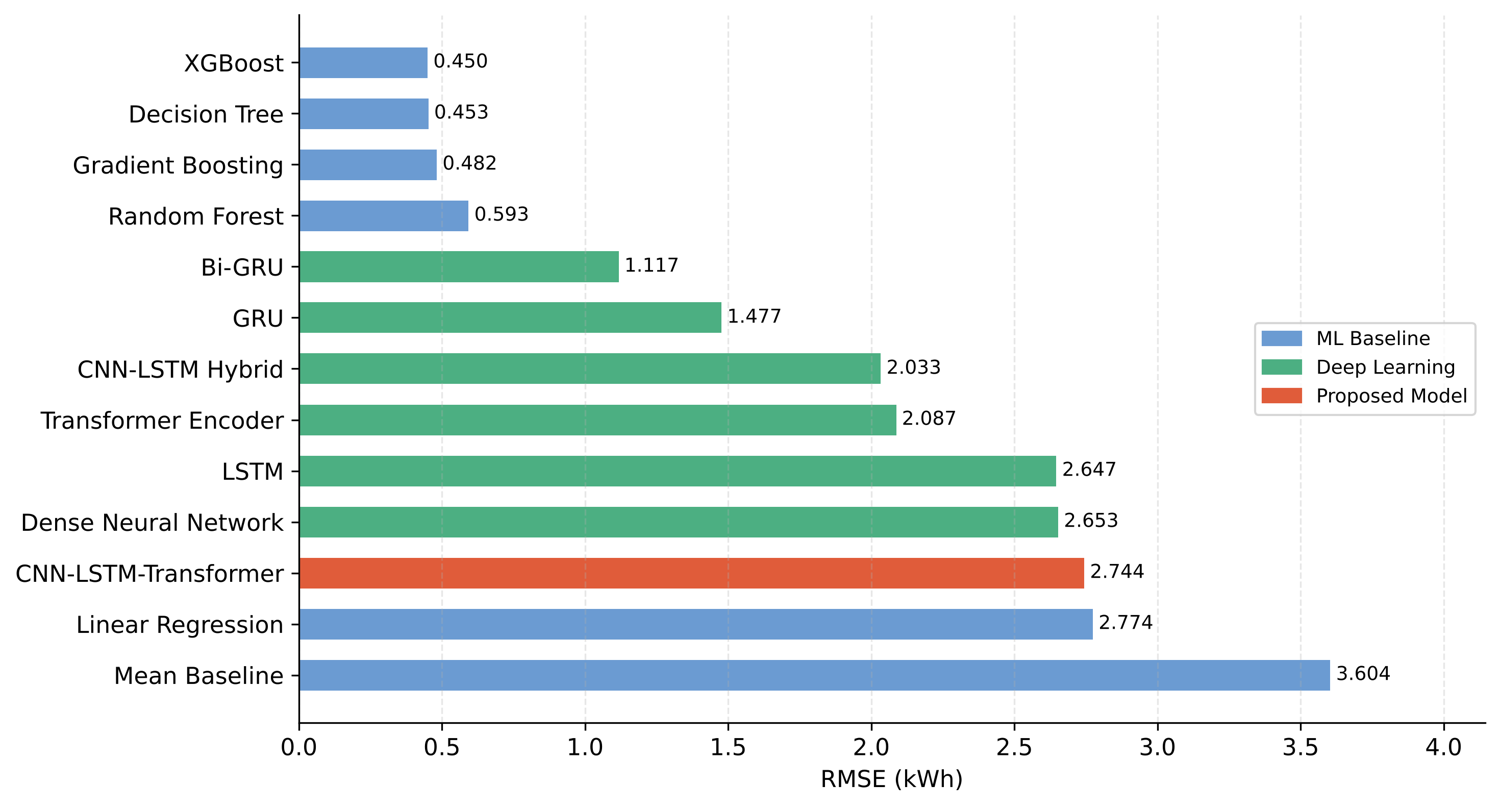

In [45]:
# Fig: RMSE bar (all 13 models)
from matplotlib.patches import Patch
pal = {'ML Baseline':'#6B9BD2','Deep Learning':'#4CAF82','Proposed Model':'#E05C3A'}
pdf = master.sort_values('RMSE', ascending=False)
fig, ax = plt.subplots(figsize=(10,6))
bars = ax.barh(pdf['Model'], pdf['RMSE'], color=[pal[c] for c in pdf['Category']], height=0.6)
for b, v in zip(bars, pdf['RMSE']): ax.text(v+0.02, b.get_y()+b.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(0, pdf['RMSE'].max()*1.15); ax.set_xlabel('RMSE (kWh)')
ax.legend(handles=[Patch(color=v, label=k) for k, v in pal.items()], loc='center right', fontsize=9)
ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=0.3, ls='--')
plt.savefig('fig1_rmse_bar.png'); plt.show()

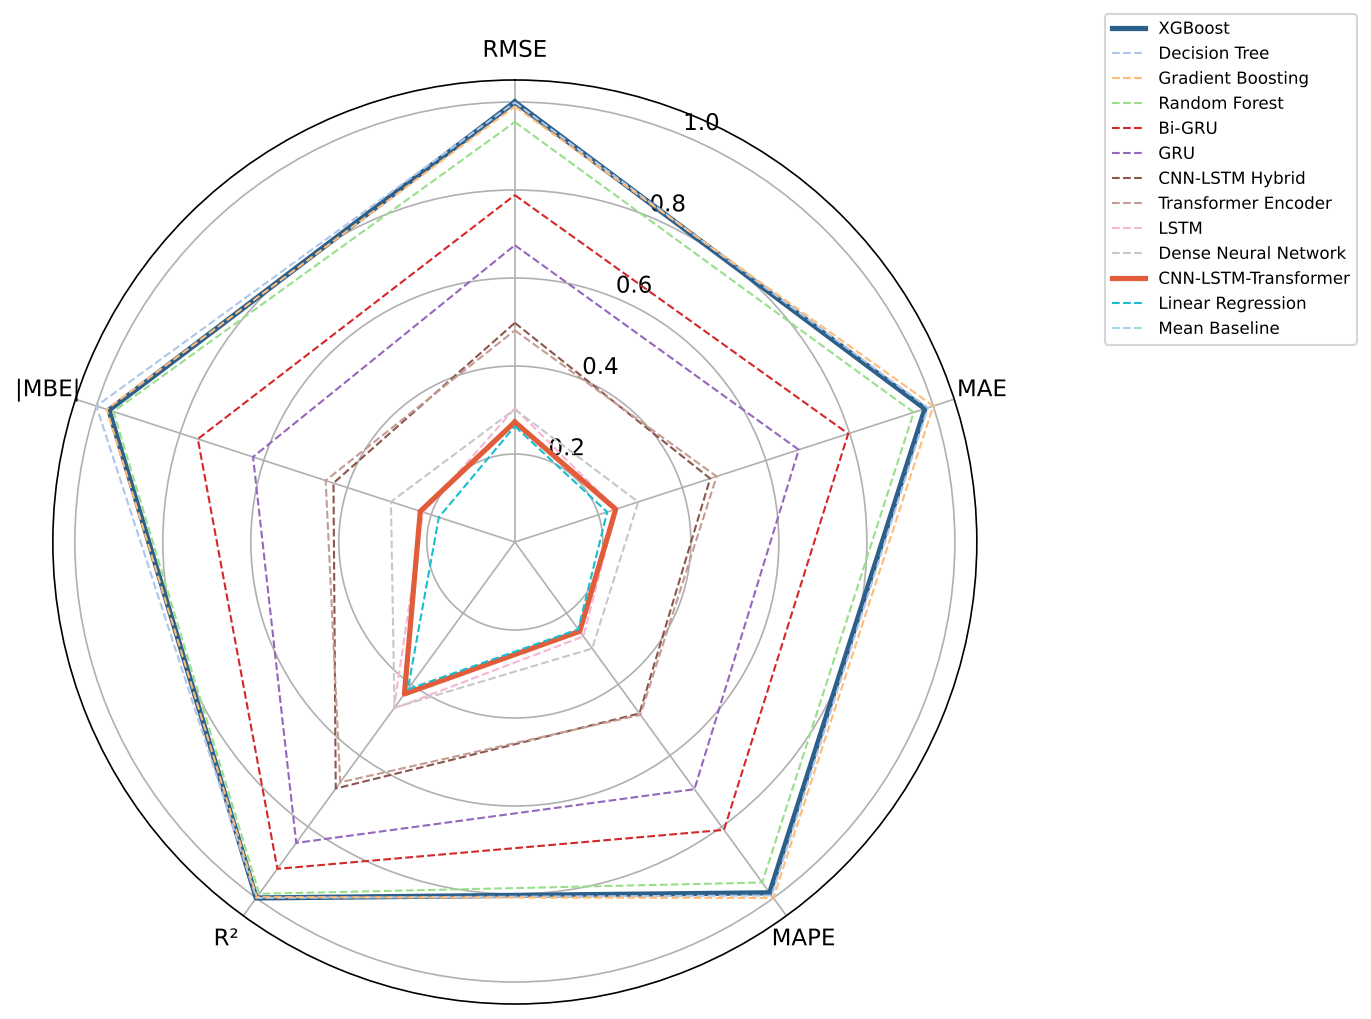

In [46]:
# Fig: radar (normalised, higher = better)
mr = ['RMSE','MAE','MAPE(%)','R2','MBE']; nm = master[['Model']+mr].copy()
for c in ['RMSE','MAE','MAPE(%)']: nm[c] = 1-(nm[c]-nm[c].min())/(nm[c].max()-nm[c].min())
nm['R2'] = (nm['R2']-nm['R2'].min())/(nm['R2'].max()-nm['R2'].min())
a = nm['MBE'].abs(); nm['MBE'] = 1-(a-a.min())/(a.max()-a.min())
ang = np.linspace(0, 2*np.pi, len(mr), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(8,8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi/2); ax.set_theta_direction(-1)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(['RMSE','MAE','MAPE','R²','|MBE|'])
cmap = plt.cm.tab20(np.linspace(0,1,len(nm)))
for i, r in nm.iterrows():
    vals = r[mr].tolist()+[r[mr[0]]]
    if r['Model'] == 'CNN-LSTM-Transformer': kw = dict(color='#E05C3A', lw=2.5, ls='-')
    elif r['Model'] == best_name:           kw = dict(color='#2C5F8A', lw=2.5, ls='-')
    else:                                    kw = dict(color=cmap[i], lw=1, ls='--')
    ax.plot(ang, vals, label=r['Model'], **kw)
ax.set_ylim(0, 1.05); ax.legend(loc='upper right', bbox_to_anchor=(1.42, 1.08), fontsize=8)
plt.savefig('fig2_radar.png'); plt.show()

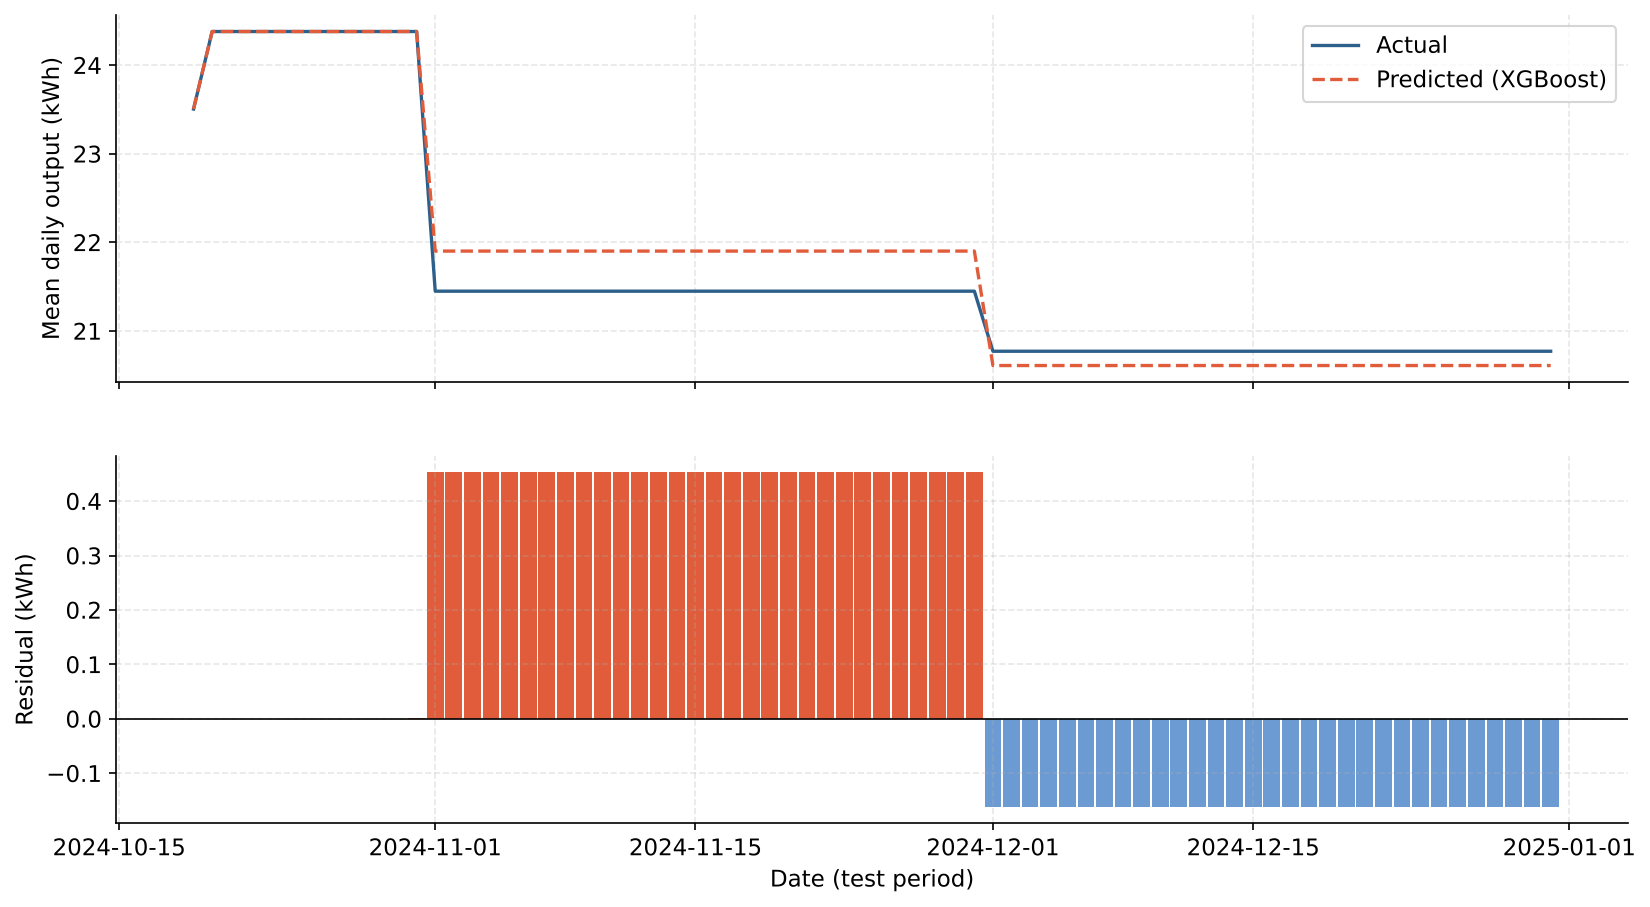

In [47]:
# Fig: daily-mean actual vs predicted (test period) + residuals, for the best model
tdf = base.loc[test_idx, ['Date','City','Panel_Type','Mount_Type','Weather',TEMP]].copy()
tdf['Actual'] = y_true_all; tdf['Pred'] = best_preds; tdf['Res'] = tdf['Pred'] - tdf['Actual']
daily = tdf.groupby('Date')[['Actual','Pred','Res']].mean()
fig, axes = plt.subplots(2, 1, figsize=(13,7), sharex=True)
axes[0].plot(daily.index, daily['Actual'], color='#2C5F8A', lw=1.6, label='Actual')
axes[0].plot(daily.index, daily['Pred'], color='#E05C3A', lw=1.6, ls='--', label=f'Predicted ({best_name})')
axes[0].set_ylabel('Mean daily output (kWh)'); axes[0].legend()
axes[1].bar(daily.index, daily['Res'], color=np.where(daily['Res']>0, '#E05C3A', '#6B9BD2'), width=0.9)
axes[1].axhline(0, color='k', lw=0.8); axes[1].set_ylabel('Residual (kWh)'); axes[1].set_xlabel('Date (test period)')
for a_ in axes: a_.spines[['top','right']].set_visible(False); a_.grid(alpha=0.3, ls='--')
plt.savefig('fig3_timeseries_residuals.png'); plt.show()

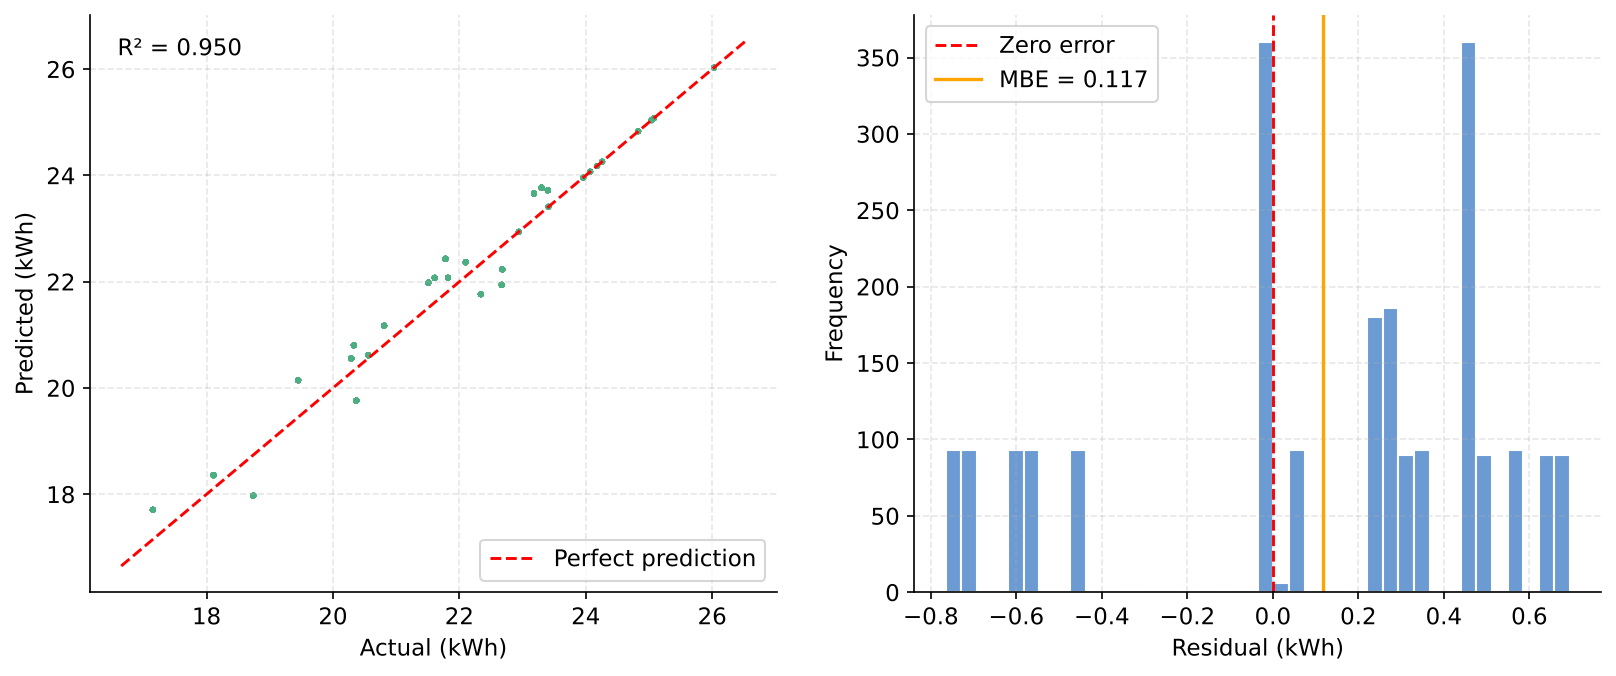

In [48]:
# Fig: scatter + residual histogram (all 2,196 test rows)
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].scatter(tdf['Actual'], tdf['Pred'], s=8, alpha=0.35, color='#4CAF82', edgecolors='none')
lo, hi = tdf[['Actual','Pred']].min().min()-0.5, tdf[['Actual','Pred']].max().max()+0.5
axes[0].plot([lo,hi], [lo,hi], 'r--', lw=1.4, label='Perfect prediction')
axes[0].set_xlabel('Actual (kWh)'); axes[0].set_ylabel('Predicted (kWh)')
axes[0].text(0.04, 0.93, f"R² = {r2_score(tdf['Actual'], tdf['Pred']):.3f}", transform=axes[0].transAxes); axes[0].legend(loc='lower right')
axes[1].hist(tdf['Res'], bins=40, color='#6B9BD2', edgecolor='white')
axes[1].axvline(0, color='red', ls='--', lw=1.4, label='Zero error')
axes[1].axvline(tdf['Res'].mean(), color='orange', lw=1.6, label=f"MBE = {tdf['Res'].mean():.3f}")
axes[1].set_xlabel('Residual (kWh)'); axes[1].set_ylabel('Frequency'); axes[1].legend()
for a_ in axes: a_.spines[['top','right']].set_visible(False); a_.grid(alpha=0.3, ls='--')
plt.savefig('fig4_scatter_residuals.png'); plt.show()

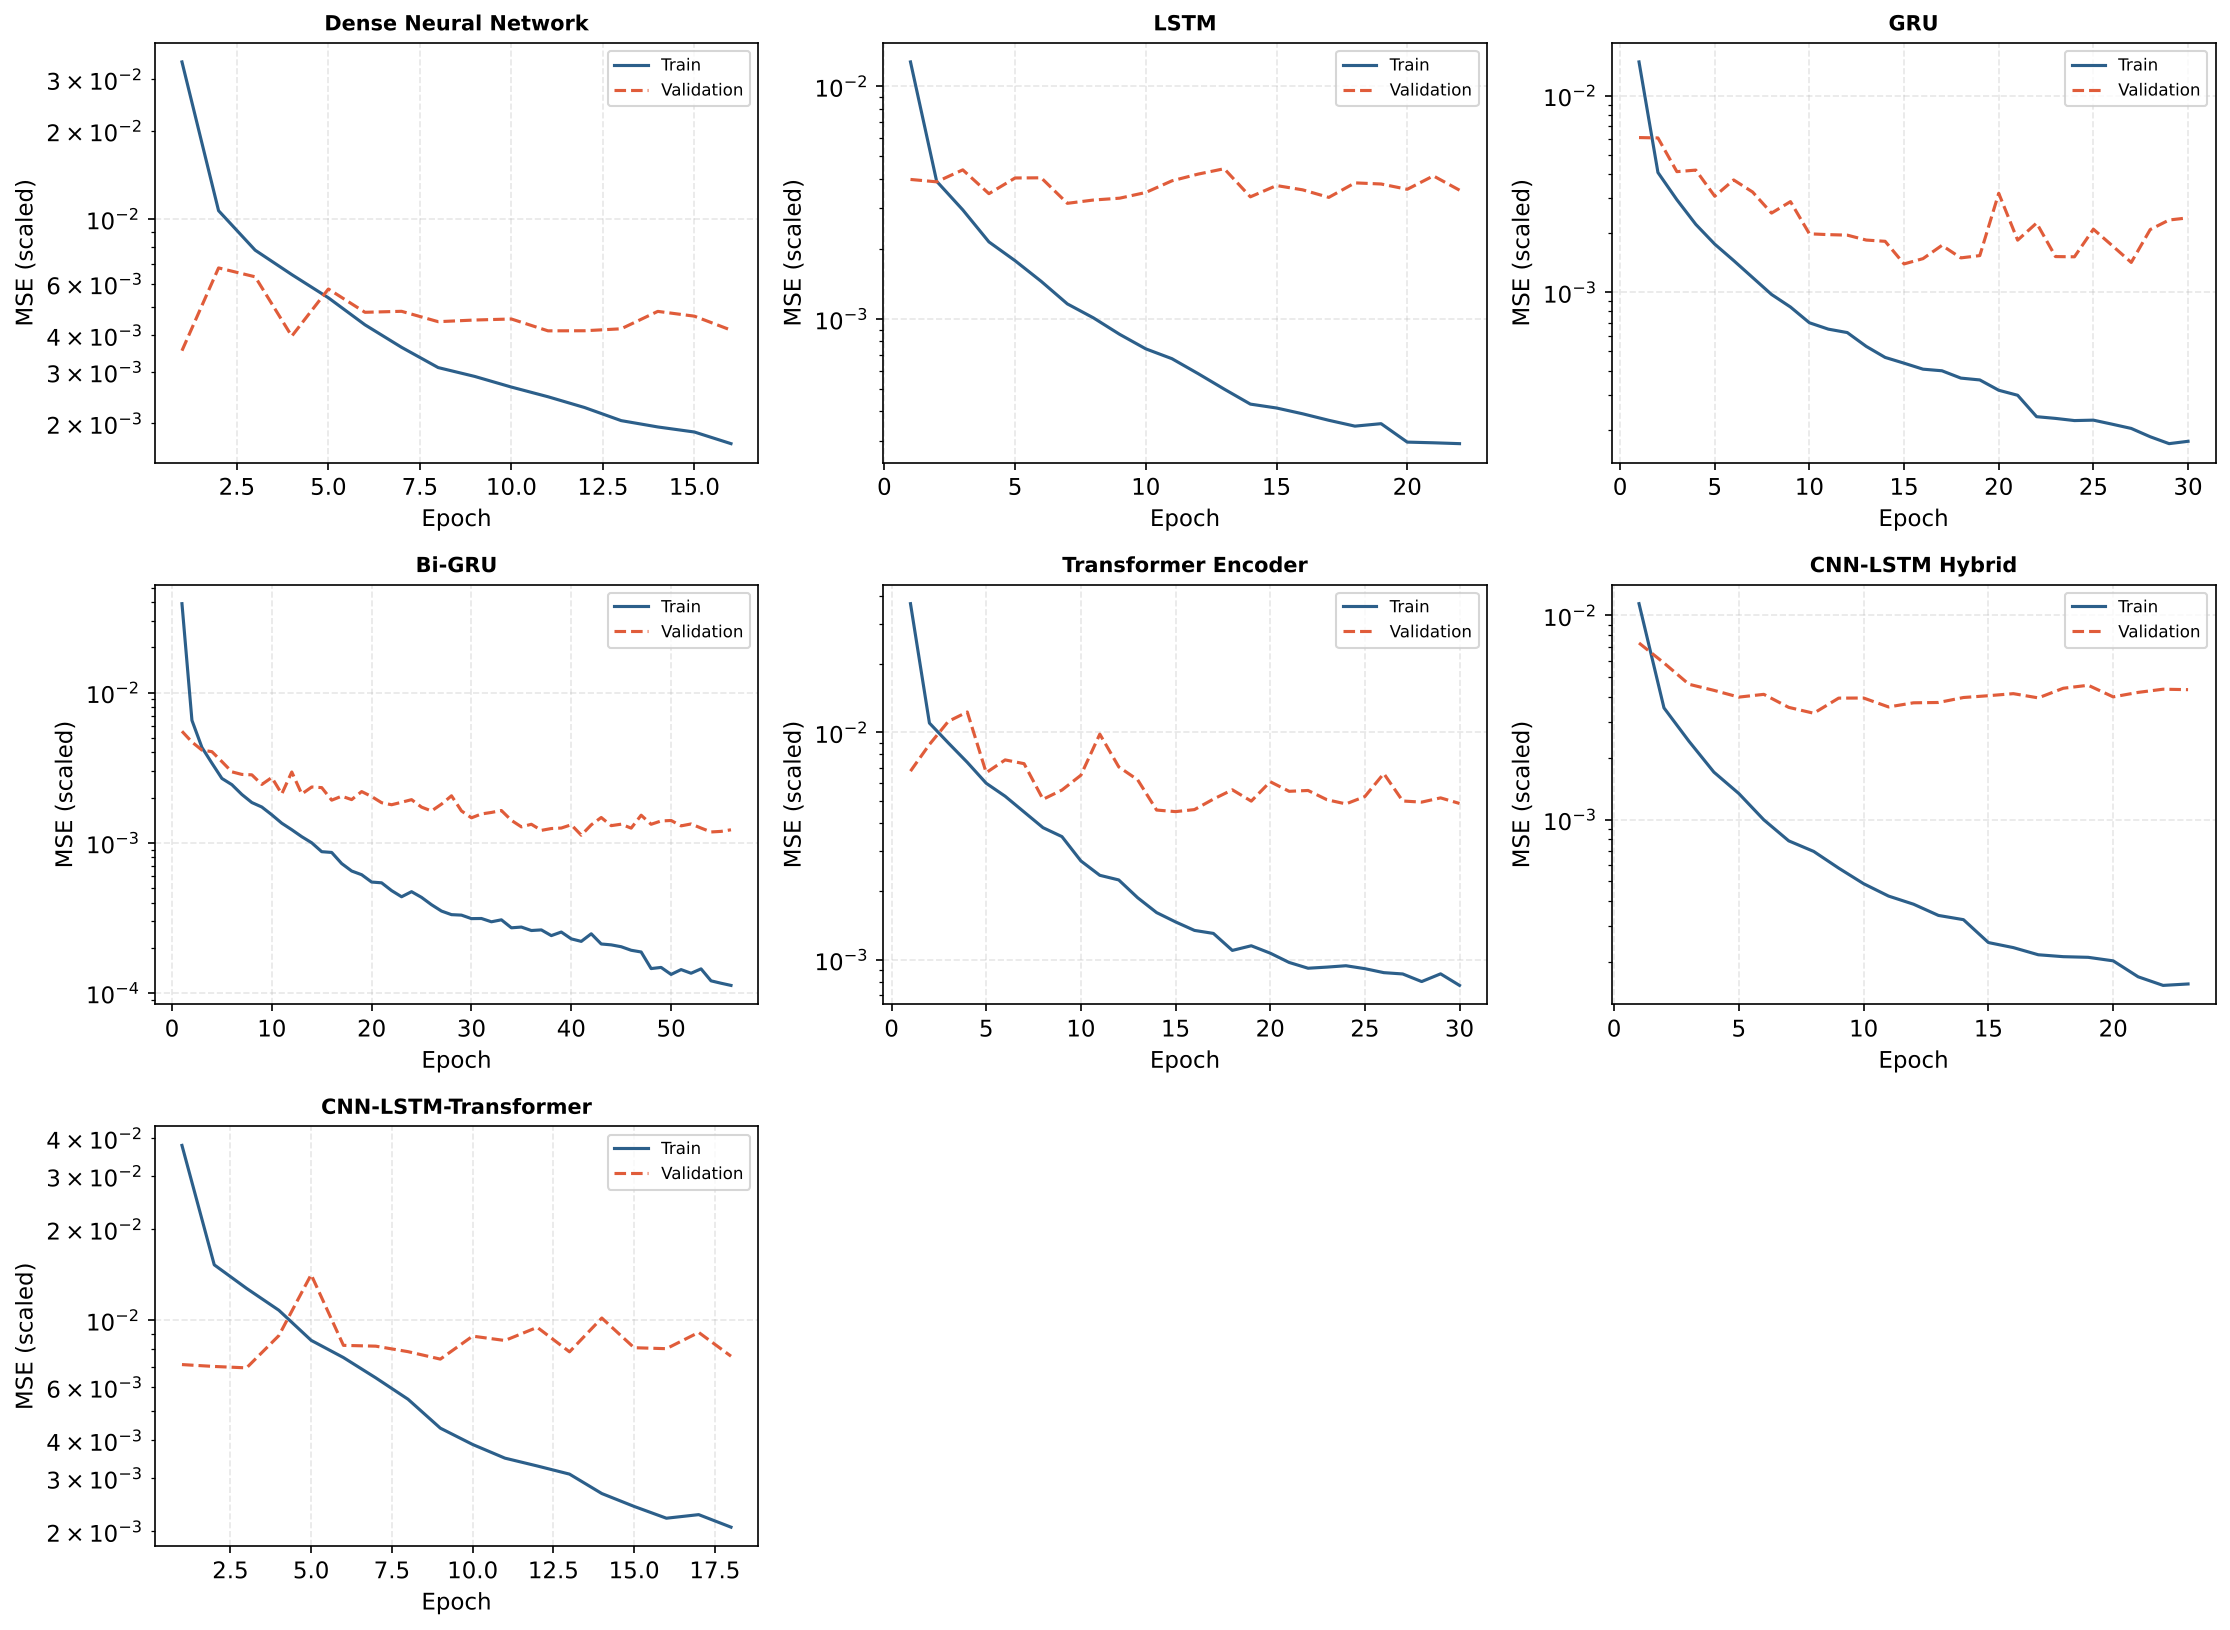

In [49]:
# Fig: learning curves (all 7 deep models)
fig, axes = plt.subplots(3, 3, figsize=(15,11)); axes = axes.flatten()
for i, (name, h) in enumerate(histories.items()):
    ep = range(1, len(h['loss'])+1)
    axes[i].plot(ep, h['loss'], color='#2C5F8A', lw=1.5, label='Train')
    axes[i].plot(ep, h['val_loss'], color='#E05C3A', lw=1.5, ls='--', label='Validation')
    axes[i].set_title(name, fontsize=10); axes[i].set_xlabel('Epoch'); axes[i].set_ylabel('MSE (scaled)')
    axes[i].set_yscale('log'); axes[i].legend(fontsize=8); axes[i].grid(alpha=0.3, ls='--')
for j in range(len(histories), len(axes)): axes[j].set_visible(False)
plt.tight_layout(); plt.savefig('fig5_learning_curves.png'); plt.show()

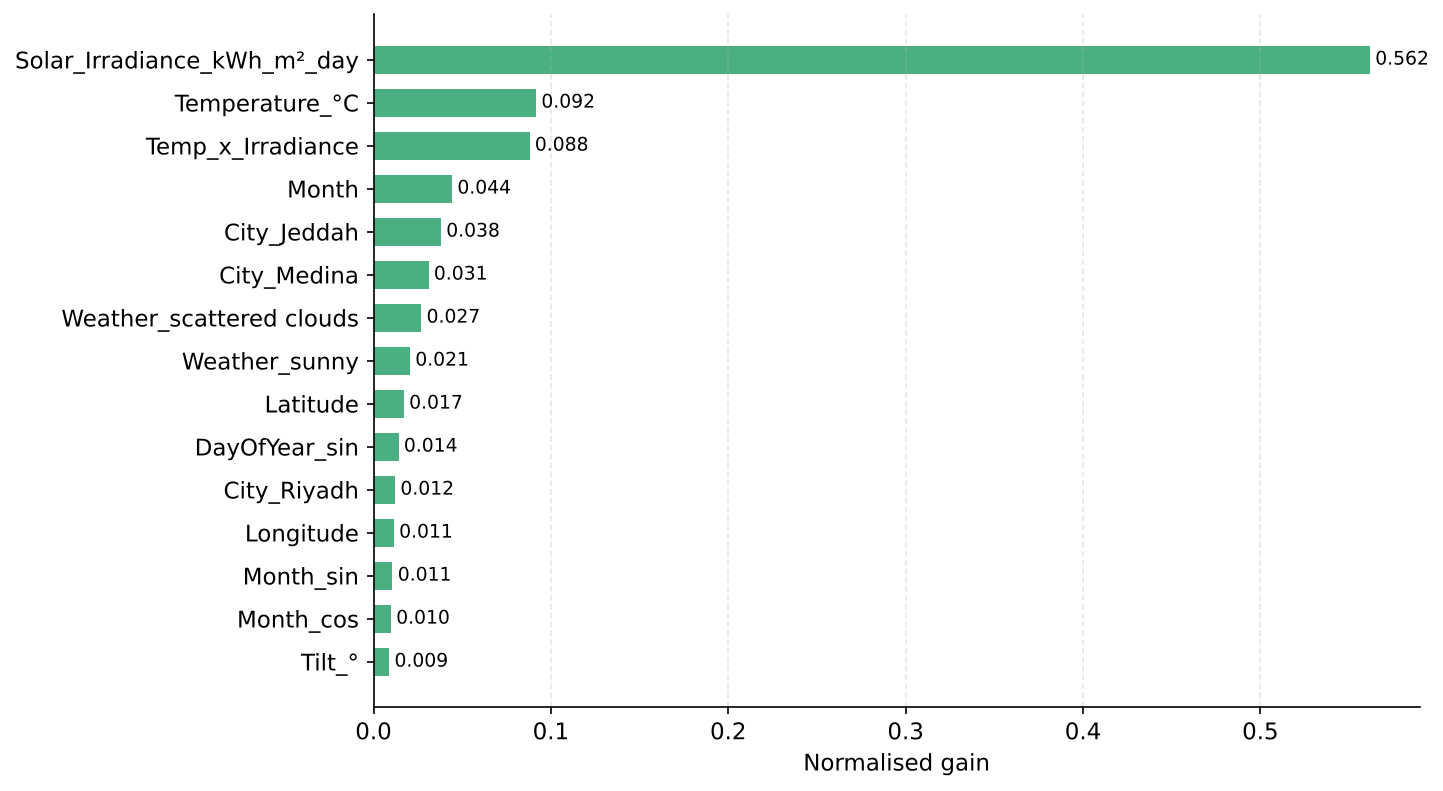

Solar_Irradiance_kWh_m²_day    0.5618
Temperature_°C                 0.0916
Temp_x_Irradiance              0.0880
Month                          0.0443
City_Jeddah                    0.0380
City_Medina                    0.0310
Weather_scattered clouds       0.0269
Weather_sunny                  0.0206
Latitude                       0.0171
DayOfYear_sin                  0.0141
City_Riyadh                    0.0122
Longitude                      0.0115
Month_sin                      0.0107
Month_cos                      0.0098
Tilt_°                         0.0088
dtype: float64


In [50]:
# Fig: XGBoost feature importance (gain)
gain = xgb_model.get_booster().get_score(importance_type='gain')
imp = pd.Series({feature_names[int(k[1:])] if k.startswith('f') and k[1:].isdigit() else k: v for k, v in gain.items()})
imp = (imp/imp.sum()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9,6))
b = ax.barh(imp.index, imp.values, color='#4CAF82', height=0.65)
for bb, v in zip(b, imp.values): ax.text(v+0.003, bb.get_y()+bb.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('Normalised gain'); ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=0.3, ls='--')
plt.savefig('fig6_feature_importance.png'); plt.show()
print(imp.sort_values(ascending=False).round(4))

          RMSE     MAE      R2  Test SD
City                                   
Medina  0.3668  0.3008  0.9268   1.3570
Riyadh  0.4554  0.4001  0.9342   1.7778
Jeddah  0.3718  0.3127  0.9124   1.2576
Mecca   0.4817  0.4256  0.8593   1.2857
Dammam  0.5464  0.4687  0.9334   2.1205


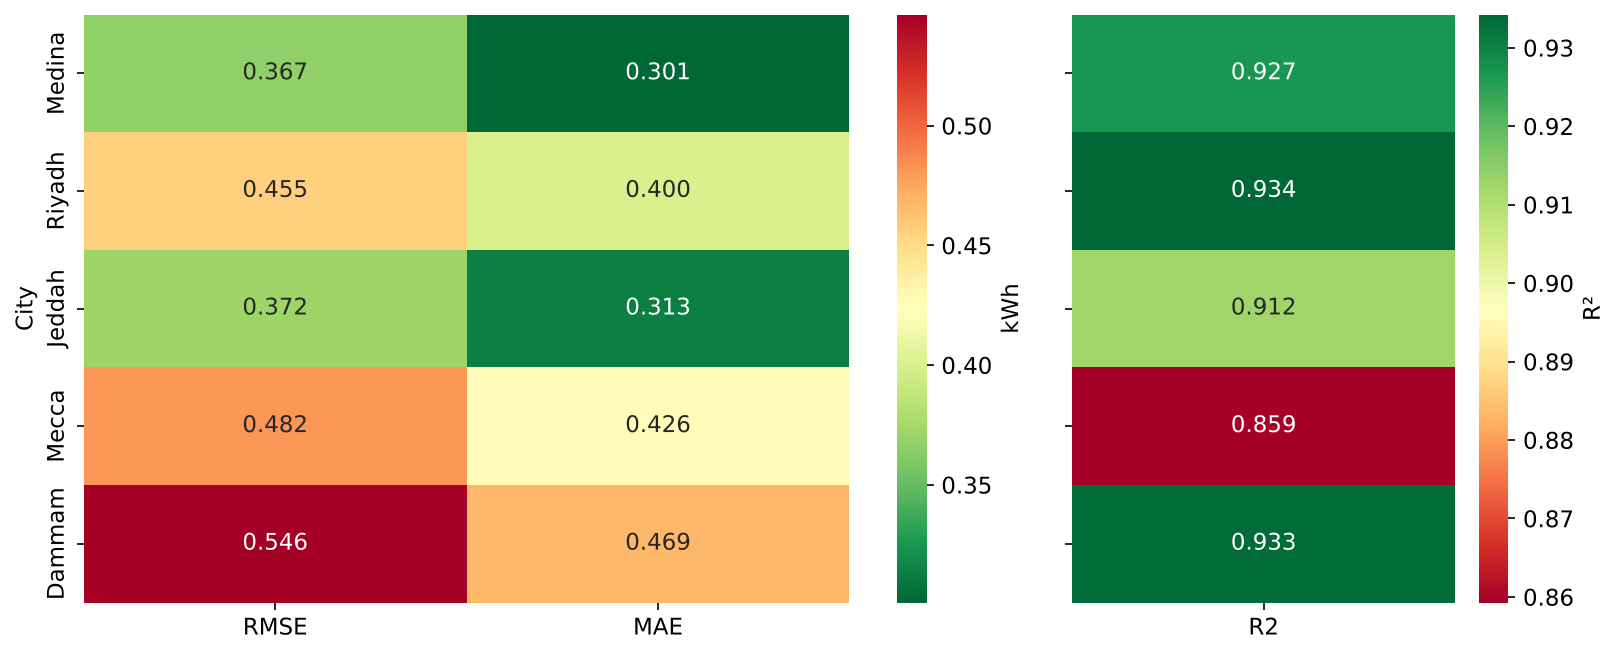

In [51]:
# Fig: city-level metrics for the best model (aligned rows)
city_order = ['Medina','Riyadh','Jeddah','Mecca','Dammam']
city_m = tdf.groupby('City').apply(lambda g: pd.Series({
    'RMSE': np.sqrt(np.mean(g['Res']**2)), 'MAE': np.mean(np.abs(g['Res'])),
    'R2': r2_score(g['Actual'], g['Pred']), 'Test SD': g['Actual'].std()})).reindex(city_order)
print(city_m.round(4)); city_m.to_csv('t5_city_metrics.csv')
fig, axes = plt.subplots(1, 2, figsize=(11,4.5), gridspec_kw={'width_ratios':[2,1]})
sns.heatmap(city_m[['RMSE','MAE']], annot=True, fmt='.3f', cmap='RdYlGn_r', ax=axes[0], cbar_kws={'label':'kWh'})
sns.heatmap(city_m[['R2']], annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[1], cbar_kws={'label':'R²'})
axes[0].set_ylabel('City'); axes[1].set_ylabel(''); axes[1].set_yticklabels([])
plt.tight_layout(); plt.savefig('fig7_city_heatmap.png'); plt.show()

Test-set temperature range: 20 - 32 °C
Walk-forward out-of-fold error by temperature band:
           RMSE     MBE     n
Band                         
≤25°C    0.3543 -0.0817  1830
26–30°C  0.6724  0.5646  1800
31–35°C  0.2241  0.0590  1860
36–38°C  0.3440  0.2592   900
>38°C    0.4081  0.1735  2760
OOF RMSE >38°C: 0.4081 | ≤38°C: 0.4411


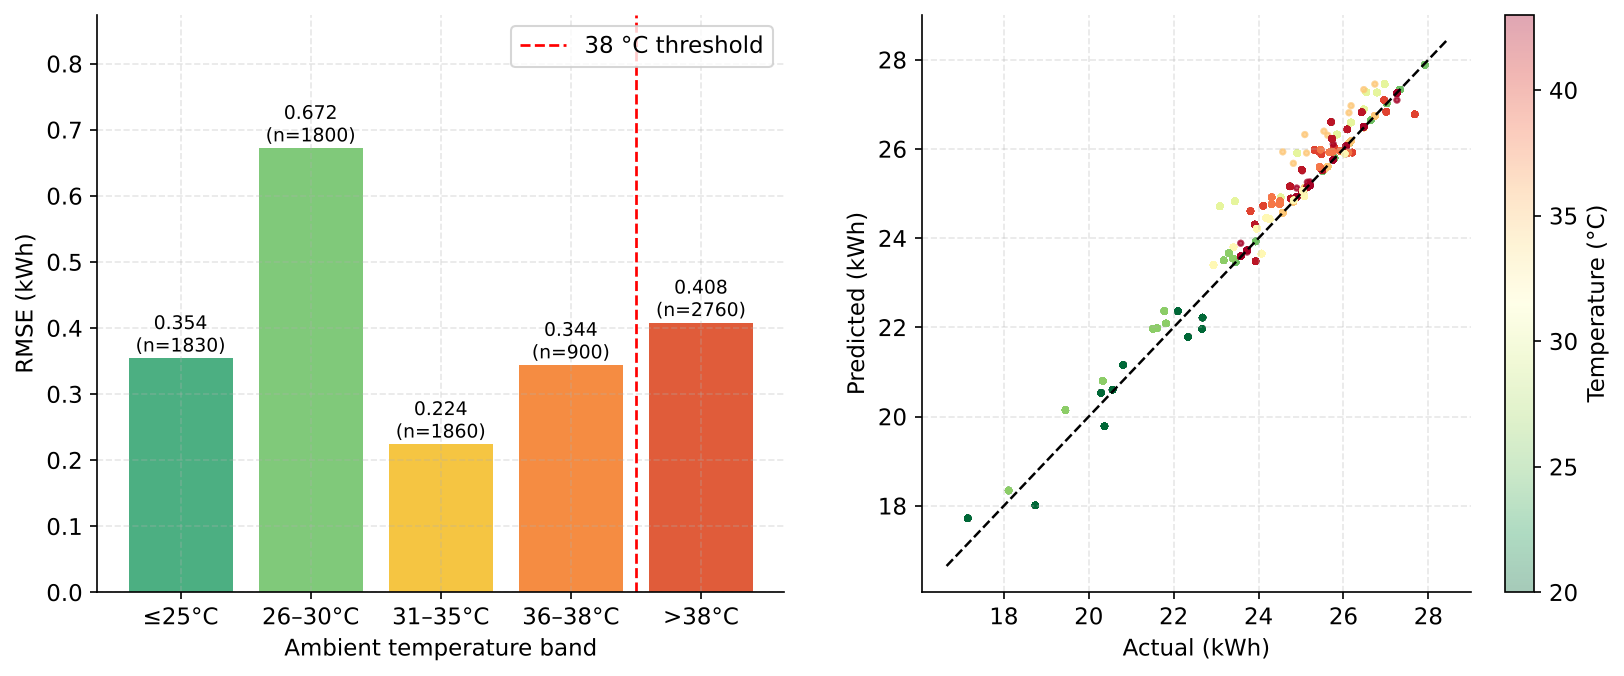

In [52]:
# Fig: error by temperature band.
# The chronological test set (19 Oct - 31 Dec) contains no day above 35 °C, so RQ4 is evaluated on the
# walk-forward out-of-fold XGBoost predictions, which cover March-December including summer.
bins, labs = [-np.inf,25,30,35,38,np.inf], ['≤25°C','26–30°C','31–35°C','36–38°C','>38°C']
print('Test-set temperature range:', tdf[TEMP].min(), '-', tdf[TEMP].max(), '°C')
odf = base.loc[oof.notna(), [TEMP, target_col]].copy(); odf['Pred'] = oof.dropna()
odf['Res'] = odf['Pred'] - odf[target_col]; odf['Band'] = pd.cut(odf[TEMP], bins=bins, labels=labs)
band = odf.groupby('Band', observed=False).agg(RMSE=('Res', lambda r: np.sqrt(np.mean(r**2))), MBE=('Res','mean'), n=('Res','size'))
print('Walk-forward out-of-fold error by temperature band:'); print(band.round(4)); band.to_csv('t5_temp_bands.csv')
hot = odf[TEMP] > 38
print(f"OOF RMSE >38°C: {np.sqrt(np.mean(odf.loc[hot,'Res']**2)):.4f} | ≤38°C: {np.sqrt(np.mean(odf.loc[~hot,'Res']**2)):.4f}")
fig, axes = plt.subplots(1, 2, figsize=(13,5))
bb = band[band['n'] > 0]
axes[0].bar(bb.index.astype(str), bb['RMSE'], color=['#4CAF82','#80C97A','#F5C542','#F58C42','#E05C3A'][:len(bb)])
for i, (v, n) in enumerate(zip(bb['RMSE'], bb['n'])): axes[0].text(i, v+0.01, f'{v:.3f}\n(n={n})', ha='center', fontsize=9)
axes[0].set_ylim(0, bb['RMSE'].max()*1.3)
axes[0].axvline(list(bb.index.astype(str)).index('>38°C')-0.5 if '>38°C' in list(bb.index.astype(str)) else len(bb)-0.5,
                color='red', ls='--', lw=1.3, label='38 °C threshold'); axes[0].legend(loc='upper right')
axes[0].set_ylabel('RMSE (kWh)'); axes[0].set_xlabel('Ambient temperature band')
sc = axes[1].scatter(odf[target_col], odf['Pred'], c=odf[TEMP], cmap='RdYlGn_r', s=6, alpha=0.35)
lo3, hi3 = odf[[target_col,'Pred']].min().min()-0.5, odf[[target_col,'Pred']].max().max()+0.5
axes[1].plot([lo3,hi3], [lo3,hi3], 'k--', lw=1.2); plt.colorbar(sc, ax=axes[1], label='Temperature (°C)')
axes[1].set_xlabel('Actual (kWh)'); axes[1].set_ylabel('Predicted (kWh)')
for a_ in axes: a_.spines[['top','right']].set_visible(False); a_.grid(alpha=0.3, ls='--')
plt.savefig('fig8_temp_degradation.png'); plt.show()

ANOVA F = 1.12e-28, p = 1.0


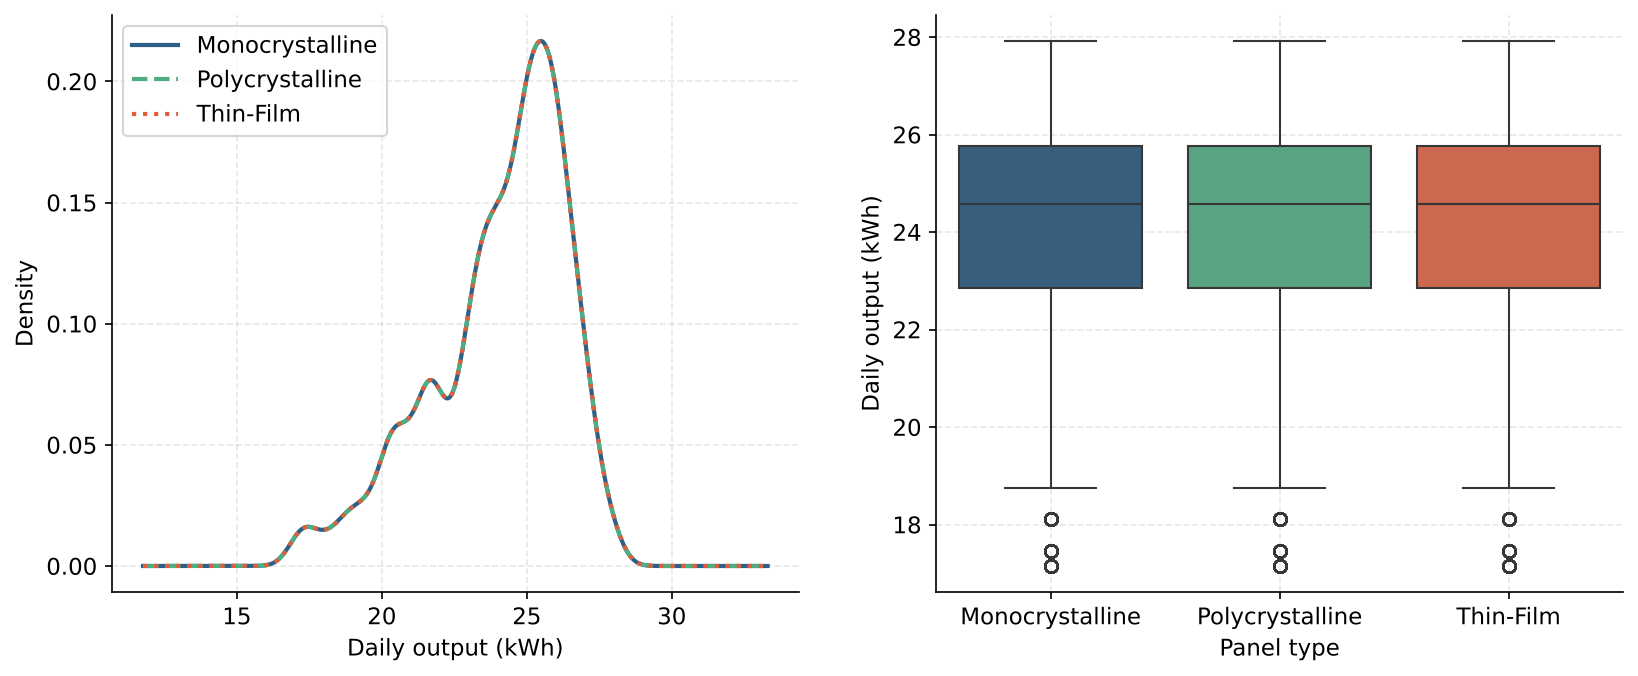

In [53]:
# Fig: panel-type finding (outputs are identical across panel types)
from scipy import stats as st
F, p_an = st.f_oneway(*[base.loc[base.Panel_Type==p, target_col] for p in base.Panel_Type.unique()])
print(f'ANOVA F = {F:.3g}, p = {p_an}')
fig, axes = plt.subplots(1, 2, figsize=(13,5))
pc = {'Monocrystalline':'#2C5F8A','Polycrystalline':'#4CAF82','Thin-Film':'#E05C3A'}
for (pt, col), ls in zip(pc.items(), ['-','--',':']):
    base.loc[base.Panel_Type==pt, target_col].plot.kde(ax=axes[0], color=col, lw=2, ls=ls, label=pt)
axes[0].set_xlabel('Daily output (kWh)'); axes[0].legend()
sns.boxplot(data=base, x='Panel_Type', y=target_col, palette=pc, ax=axes[1], order=list(pc))
axes[1].set_xlabel('Panel type'); axes[1].set_ylabel('Daily output (kWh)')
for a_ in axes: a_.spines[['top','right']].set_visible(False); a_.grid(alpha=0.3, ls='--')
plt.savefig('fig9_panel_type.png'); plt.show()

In [54]:
# Ablation table (deep-learning components)
abl = master[master.Model.isin(['LSTM','Transformer Encoder','CNN-LSTM Hybrid','CNN-LSTM-Transformer'])][['Model','RMSE','MAE','R2','Params']].copy()
abl['dRMSE vs LSTM'] = float(master.loc[master.Model=='LSTM','RMSE'].iloc[0]) - abl['RMSE']
print(abl.round(4).to_string(index=False)); abl.to_csv('t5_ablation.csv', index=False)

               Model   RMSE    MAE      R2   Params  dRMSE vs LSTM
     CNN-LSTM Hybrid 2.0332 1.7908 -0.0255  55777.0         0.6134
 Transformer Encoder 2.0870 1.7487 -0.0805  75729.0         0.5596
                LSTM 2.6466 2.4079 -0.7377  52705.0         0.0000
CNN-LSTM-Transformer 2.7441 2.4103 -0.8680 260417.0        -0.0974


### Modality ablation (multimodal fusion analysis)
XGBoost is retrained on the same split (a) without each modality and (b) with each modality alone.

In [39]:
from scipy import stats
modalities = {
    'Meteorological': [c for c in feature_names if c.startswith(('Temperature','Solar_Irradiance','Temp_High','Temp_x'))],
    'Sky state':      [c for c in feature_names if c.startswith('Weather_')],
    'Geospatial':     [c for c in feature_names if c.startswith(('City_','Latitude','Longitude'))],
    'Configuration':  [c for c in feature_names if c.startswith(('Panel_','Mount_','Tilt'))],
    'Temporal':       [c for c in feature_names if c.startswith(('Month','DayOfYear'))],
}
assert sorted(sum(modalities.values(), [])) == sorted(feature_names)
for k, v in modalities.items(): print(f'{k:15s} {len(v):2d} features')
def fit_xgb(cols):
    mdl = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                           reg_alpha=0.1, random_state=SEED, n_jobs=-1, verbosity=0).fit(X_train[cols], y_train)
    return mdl.predict(X_test[cols])
cellk = [base.loc[test_idx,'City'].values, base.loc[test_idx,'Date'].dt.month.values, base.loc[test_idx,'Mount_Type'].values]
cmae = lambda p: pd.Series(np.abs(p - y_test)).groupby(cellk).mean().values
full_cm = cmae(preds['XGBoost']); abl_rows = []
for setting, cols_fn in [('All modalities', lambda k: feature_names)] + \
        [(f'without {k}', (lambda k: [c for c in feature_names if c not in modalities[k]])) for k in modalities] + \
        [(f'{k} only', (lambda k: modalities[k])) for k in modalities]:
    key = setting.replace('without ','').replace(' only','')
    cols = cols_fn(key); p = fit_xgb(cols); mt = metrics(setting, y_test, p)
    w = 1.0 if setting=='All modalities' or np.allclose(cmae(p), full_cm) else stats.wilcoxon(full_cm, cmae(p)).pvalue
    abl_rows.append({**mt, 'n_features': len(cols), 'Wilcoxon p vs all (cells)': w})
mod_df = pd.DataFrame(abl_rows); mod_df.to_csv('t5_modality_ablation.csv', index=False)
print(mod_df[['Model','n_features','RMSE','MAE','R2','MBE','Wilcoxon p vs all (cells)']].round(4).to_string(index=False))

Meteorological   4 features
Sky state        3 features
Geospatial       6 features
Configuration    5 features
Temporal         6 features


                 Model  n_features   RMSE    MAE      R2     MBE  Wilcoxon p vs all (cells)
        All modalities          24 0.4499 0.3818  0.9498  0.1172                     1.0000
without Meteorological          20 3.1511 2.6567 -1.4633  2.6563                     0.0000
     without Sky state          21 0.5381 0.4499  0.9282  0.2708                     0.1004
    without Geospatial          18 0.4334 0.3309  0.9534 -0.0284                     0.6408
 without Configuration          19 0.5207 0.4396  0.9327  0.1656                     0.0093
      without Temporal          18 0.4561 0.3722  0.9484  0.0998                     0.7922
   Meteorological only           4 0.6287 0.5239  0.9020  0.1107                     0.0024
        Sky state only           3 4.2753 3.7396 -3.5344  3.6146                     0.0000
       Geospatial only           6 3.5147 3.0652 -2.0645  2.9884                     0.0000
    Configuration only           5 3.6193 3.0755 -2.2496  2.9913                

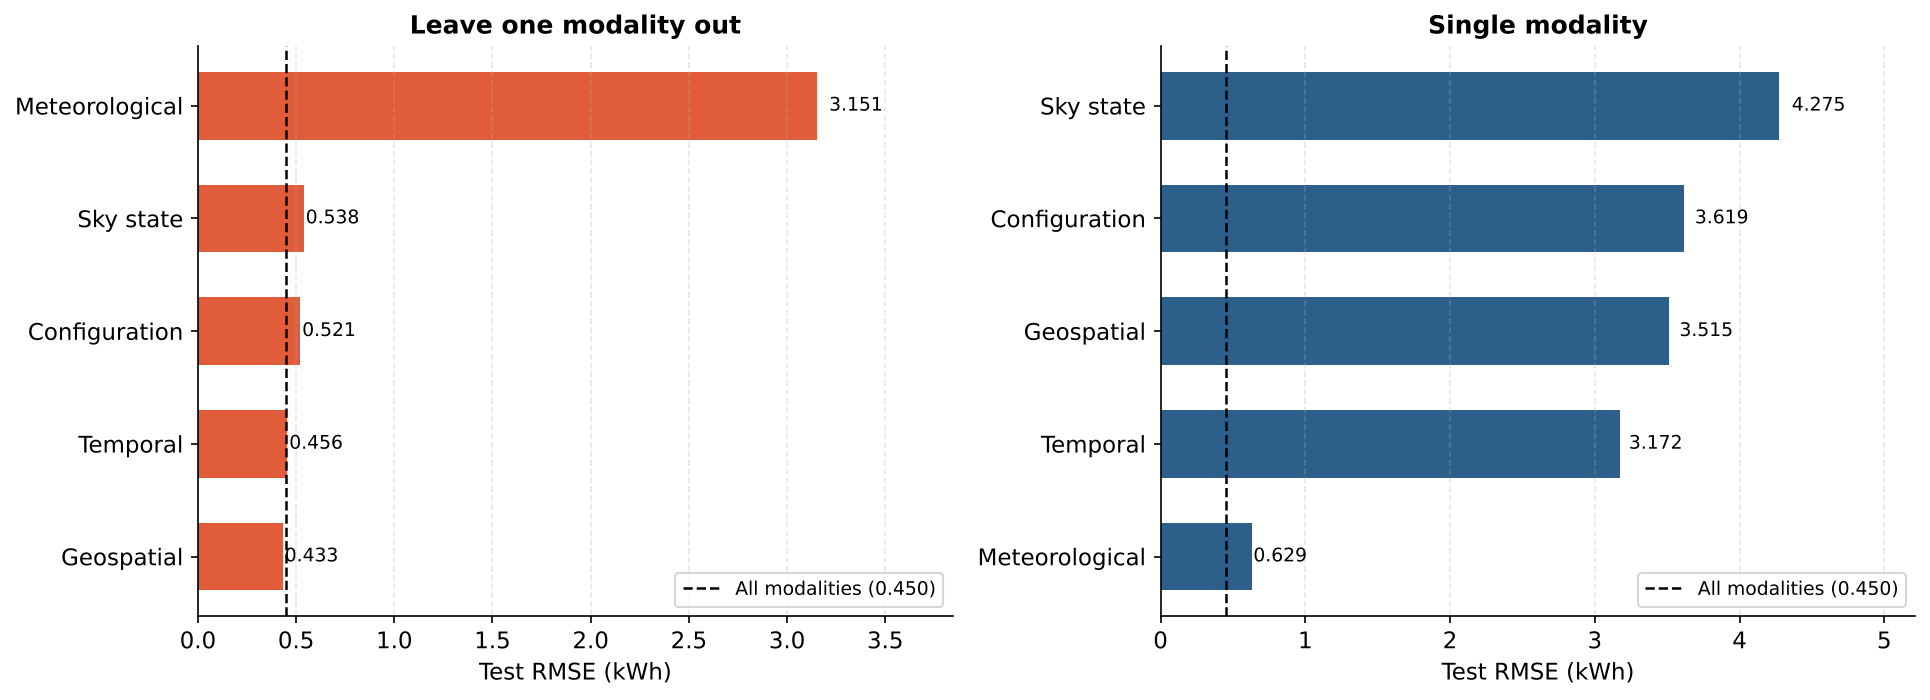

In [40]:
# Fig: modality ablation
fig, axes = plt.subplots(1, 2, figsize=(13,4.8), sharex=False)
lo_ = mod_df[mod_df.Model.str.startswith('without')].copy(); so_ = mod_df[mod_df.Model.str.endswith('only')].copy()
full_rmse = float(mod_df.loc[mod_df.Model=='All modalities','RMSE'].iloc[0])
for ax, d, col, ttl in [(axes[0], lo_, '#E05C3A', 'Leave one modality out'), (axes[1], so_, '#2C5F8A', 'Single modality')]:
    d = d.sort_values('RMSE'); lab = d.Model.str.replace('without ','').str.replace(' only','')
    b = ax.barh(lab, d.RMSE, color=col, height=0.6)
    for bb, v in zip(b, d.RMSE): ax.text(v*1.02, bb.get_y()+bb.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
    ax.axvline(full_rmse, color='k', ls='--', lw=1.2, label=f'All modalities ({full_rmse:.3f})')
    ax.set_xlabel('Test RMSE (kWh)'); ax.set_title(ttl); ax.legend(loc='lower right', fontsize=9)
    ax.set_xlim(0, d.RMSE.max()*1.22); ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=0.3, ls='--')
plt.tight_layout(); plt.savefig('fig10_modality_ablation.png'); plt.show()

### Spark scalability
The dataset is replicated k times (k = 1 ... 500; up to ~5.5 M rows) and the same feature-engineering and
aggregation workload is timed in Spark (local mode, all cores) and pandas.

In [37]:
import time, shutil, tempfile
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName('KSA_scaling').config('spark.driver.memory','4g')
         .config('spark.sql.shuffle.partitions','8').config('spark.ui.enabled','false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
raw = base[['Date','City','Weather','Panel_Type','Mount_Type',TEMP,IRR,target_col]].rename(
    columns={TEMP:'Temp', IRR:'Irr', target_col:'Out'})
tmp = tempfile.mkdtemp(); scale_rows = []
def pandas_job(pdf):
    pdf = pdf.copy(); pdf['Month'] = pd.to_datetime(pdf['Date']).dt.month
    pdf['Month_sin'] = np.sin(2*np.pi*pdf['Month']/12); pdf['TxI'] = pdf['Temp']*pdf['Irr']; pdf['Hot'] = (pdf['Temp']>38).astype(int)
    a = pdf.groupby(['City','Month','Mount_Type']).agg(out=('Out','mean'), sd=('Out','std'), irr=('Irr','mean'), txi=('TxI','mean'))
    b = pdf.groupby(['City','Weather']).agg(out=('Out','mean'), n=('Out','size'))
    return len(a) + len(b)
def spark_job(path):
    s = spark.read.parquet(path)
    s = (s.withColumn('Month', F.month('Date')).withColumn('Month_sin', F.sin(2*np.pi*F.col('Month')/12))
          .withColumn('TxI', F.col('Temp')*F.col('Irr')).withColumn('Hot', (F.col('Temp')>38).cast('int')))
    a = s.groupBy('City','Month','Mount_Type').agg(F.mean('Out'), F.stddev('Out'), F.mean('Irr'), F.mean('TxI')).count()
    b = s.groupBy('City','Weather').agg(F.mean('Out'), F.count('Out')).count()
    return a + b
for k in [1, 5, 10, 25, 50, 100, 250, 500]:
    pdf = pd.concat([raw]*k, ignore_index=True); path = f'{tmp}/k{k}.parquet'
    spark.createDataFrame(pdf).write.mode('overwrite').parquet(path)
    spark_job(path)                                         # warm-up
    t0 = time.perf_counter(); r_s = spark_job(path); ts_ = time.perf_counter() - t0
    t0 = time.perf_counter(); r_p = pandas_job(pdf); tp_ = time.perf_counter() - t0
    assert r_s == r_p
    scale_rows.append({'Replication':k,'Rows':len(pdf),'Spark (s)':ts_,'pandas (s)':tp_, 'Spark rows/s':len(pdf)/ts_})
    print(scale_rows[-1])
spark.stop(); shutil.rmtree(tmp, ignore_errors=True)
scale_df = pd.DataFrame(scale_rows); scale_df.to_csv('t5_spark_scaling.csv', index=False)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=37111 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=37111 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/25 01:06:53 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/25 01:06:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/25 01:06:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


...

{'Replication': 25, 'Rows': 274500, 'Spark (s)': 0.9120964489998187, 'pandas (s)': 0.18400008600019646, 'Spark rows/s': 300955.0144625709}


{'Replication': 50, 'Rows': 549000, 'Spark (s)': 0.7767426979999073, 'pandas (s)': 0.2568077800001447, 'Spark rows/s': 706797.7612324661}


{'Replication': 100, 'Rows': 1098000, 'Spark (s)': 0.6563022899999851, 'pandas (s)': 0.5088154290001512, 'Spark rows/s': 1673009.5517418124}


{'Replication': 250, 'Rows': 2745000, 'Spark (s)': 1.2353563090000534, 'pandas (s)': 1.366451140999743, 'Spark rows/s': 2222030.9881461747}


{'Replication': 500, 'Rows': 5490000, 'Spark (s)': 1.6393841590002012, 'pandas (s)': 2.3295853119998355, 'Spark rows/s': 3348818.4998372467}


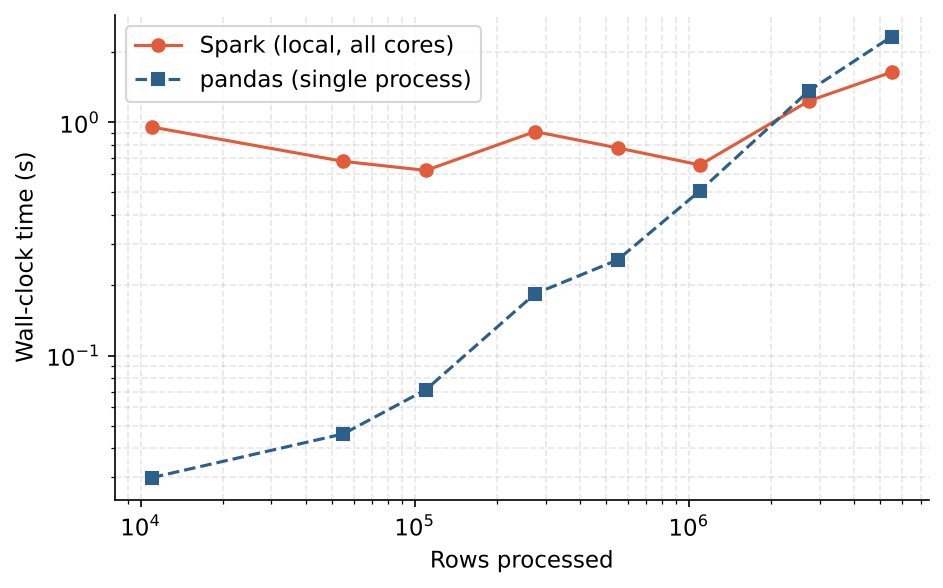

In [38]:
fig, ax = plt.subplots(figsize=(7,4.2))
ax.plot(scale_df['Rows'], scale_df['Spark (s)'], 'o-', color='#E05C3A', label='Spark (local, all cores)')
ax.plot(scale_df['Rows'], scale_df['pandas (s)'], 's--', color='#2C5F8A', label='pandas (single process)')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Rows processed'); ax.set_ylabel('Wall-clock time (s)')
ax.legend(); ax.grid(alpha=0.3, ls='--', which='both'); ax.spines[['top','right']].set_visible(False)
plt.savefig('fig11_spark_scaling.png'); plt.show()

In [55]:
import platform, importlib
for pkg in ['numpy','pandas','sklearn','xgboost','tensorflow','scipy','matplotlib','seaborn']:
    print(f'{pkg:11s}', importlib.import_module(pkg).__version__)
print('Python', platform.python_version(), '| SEED', SEED)

numpy       2.5.3
pandas      3.0.5
sklearn     1.9.1
xgboost     3.4.1
tensorflow  2.21.0
scipy       1.18.1
matplotlib  3.11.2
seaborn     0.13.2
Python 3.13.17 | SEED 42
